# Load and Inspect Data

In [2]:
# Import libraries and set data location
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Directory containing the CSV files from cbb_pipeline.py
DATA_DIR = Path("cbb_data")

In [3]:
# Load the feature configuration

with open(DATA_DIR / "feature_columns.json") as f:
    config = json.load(f)

# The pipeline's normalized feature list identifies
# which raw features are intended for modeling.
raw_features = [
    col.removeprefix("z_")
    for col in config["normalized_features"]
]

missing_features = config["missing_indicators"]

feature_cols = raw_features + missing_features
target_col = config["target"]

print("Number of predictors:", len(feature_cols))
print("Target:", target_col)
#print("Feature columns", feature_cols)

Number of predictors: 267
Target: target_home_margin


In [4]:
# Load training and validation seasons (No 2025 or 2026 they are for tests)
# Season numbers refer to the ending year. Example 2017 = 2016-17 season, 2024 = 2023-24 season.

train_seasons = range(2017, 2024)
validation_season = 2024

def load_season(year):
    filename = DATA_DIR / f"games_{year-1}_{year}.csv"
    return pd.read_csv(filename)

# Combine all training seasons
train_df = pd.concat([load_season(year) for year in train_seasons], ignore_index=True)

# Load the validation season separately
val_df = load_season(validation_season)

print("Training games:", len(train_df))
print("Validation games:", len(val_df))

Training games: 37041
Validation games: 5726


In [5]:
# Create predictor and target data frame for both the training and validation data
X_train = train_df[feature_cols].copy()
y_train = train_df[target_col].copy()

X_val = val_df[feature_cols].copy()
y_val = val_df[target_col].copy()

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

print("\nMissing values in training:")
print(X_train.isna().sum().sort_values(ascending=False).head(10))

X_train: (37041, 267)
X_val: (5726, 267)

Missing values in training:
diff_last5_sor           2870
diff_avg_sos_win         2870
diff_avg_sor             2870
diff_last5_sos_win       2870
diff_last5_sos_margin    2870
diff_avg_sos_margin      2870
away_avg_sos_margin      2457
away_last5_sos_margin    2457
away_avg_sor             2457
away_avg_sos_win         2457
dtype: int64


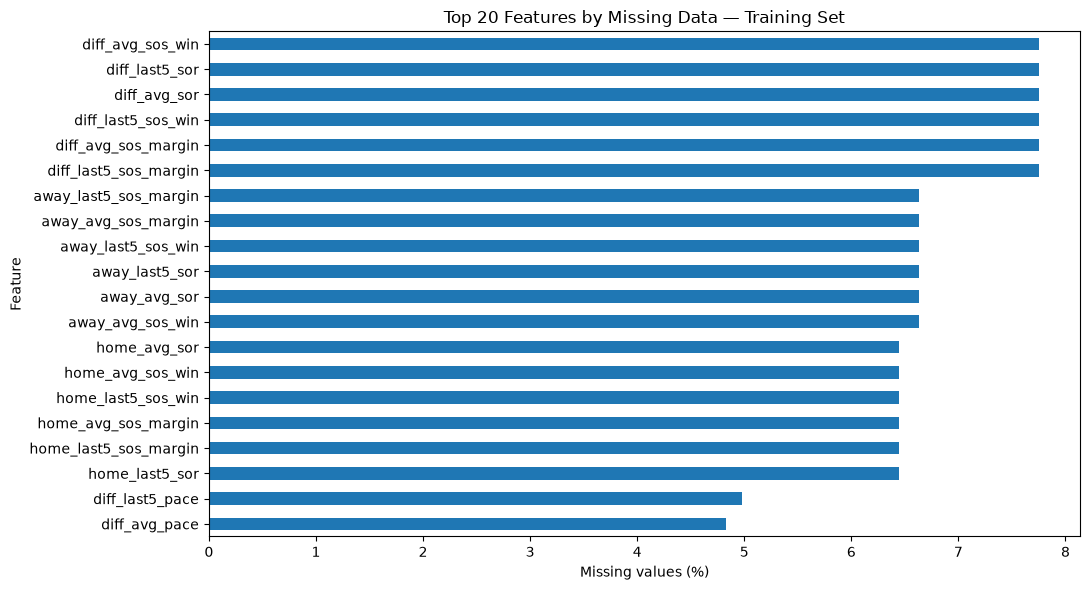

In [6]:
# Visualize missing values
# Percentage of missing values for each feature
missing_pct = X_train.isna().mean() * 100

# Show the 20 features with the most missing values
top_missing = missing_pct.sort_values(ascending=False).head(20)

plt.figure(figsize=(11, 6))
top_missing.sort_values().plot(kind="barh")

plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.title("Top 20 Features by Missing Data — Training Set")
plt.tight_layout()
plt.show()

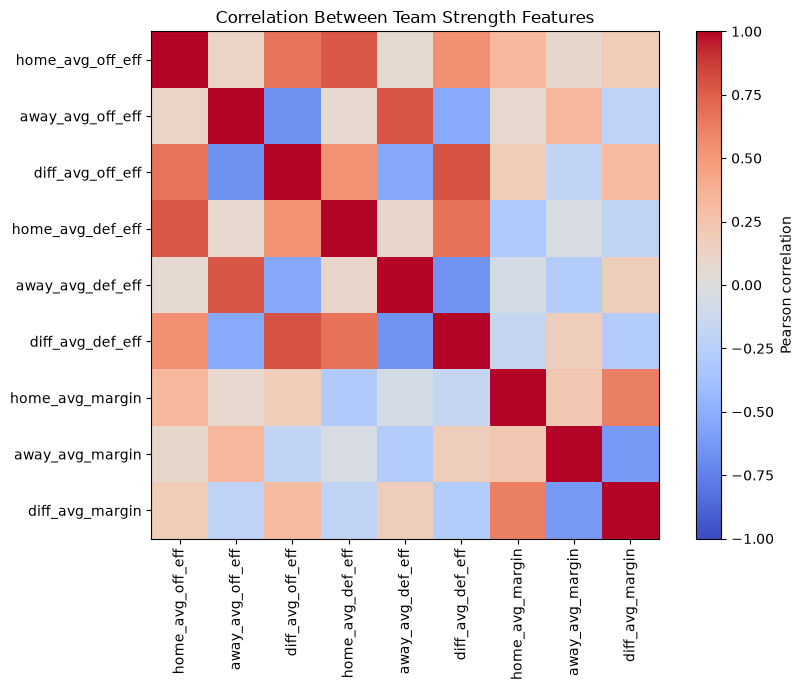

In [7]:
# Inspect feature correlations
efficiency_features = [
    "home_avg_off_eff",
    "away_avg_off_eff",
    "diff_avg_off_eff",
    "home_avg_def_eff",
    "away_avg_def_eff",
    "diff_avg_def_eff",
    "home_avg_margin",
    "away_avg_margin",
    "diff_avg_margin"
]

corr = X_train[efficiency_features].corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Between Team Strength Features")
plt.tight_layout()
plt.show()

In [8]:
# Inspect specific correlations numerically
pairs = [
    ("home_avg_off_eff", "home_avg_def_eff"),
    ("away_avg_off_eff", "away_avg_def_eff"),
    ("home_avg_off_eff", "home_avg_margin"),
    ("home_avg_def_eff", "home_avg_margin"),
    ("diff_avg_off_eff", "diff_avg_margin"),
    ("diff_avg_def_eff", "diff_avg_margin"),
]

for a, b in pairs:
    r = X_train[[a, b]].corr().iloc[0, 1]
    print(f"{a} vs {b}: {r:.3f}")

home_avg_off_eff vs home_avg_def_eff: 0.780
away_avg_off_eff vs away_avg_def_eff: 0.789
home_avg_off_eff vs home_avg_margin: 0.325
home_avg_def_eff vs home_avg_margin: -0.293
diff_avg_off_eff vs diff_avg_margin: 0.299
diff_avg_def_eff vs diff_avg_margin: -0.277


# Establish Baseline Performance MAE

In [9]:
# Calculate the zero margin baseline (All games a tie)
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict a zero-point margin for every validation game.
zero_predictions = np.zeros(len(y_val))

# Calculate the average absolute prediction error.
zero_mae = mean_absolute_error(y_val, zero_predictions)

# RMSE penalizes large prediction errors more heavily.
zero_rmse = np.sqrt(mean_squared_error(y_val, zero_predictions))

print(f"Zero-margin MAE:  {zero_mae:.3f}")
print(f"Zero-margin RMSE: {zero_rmse:.3f}")

Zero-margin MAE:  12.062
Zero-margin RMSE: 15.197


In [10]:
# Calculate the sportsbook baseline
# Keep only games where a historical market line is available.
market_mask = (val_df["market_home_margin"].notna()& val_df[target_col].notna())

# Actual game margins for games with sportsbook lines.
y_market = val_df.loc[market_mask, target_col]

# Sportsbook's predicted home-team margin.
market_predictions = val_df.loc[market_mask, "market_home_margin"]

market_mae = mean_absolute_error(y_market, market_predictions)

market_rmse = np.sqrt(mean_squared_error(y_market, market_predictions))

print(f"Market games: {market_mask.sum():,}")
print(f"Market coverage: {market_mask.mean():.1%}")
print(f"Sportsbook MAE:  {market_mae:.3f}")
print(f"Sportsbook RMSE: {market_rmse:.3f}")

Market games: 5,304
Market coverage: 92.6%
Sportsbook MAE:  8.873
Sportsbook RMSE: 11.195


In [11]:
# Fairly compare the 2 MAE and RMSE 
# Zero-margin predictions on only games with market lines.
zero_market_predictions = np.zeros(len(y_market))

zero_market_mae = mean_absolute_error(y_market, zero_market_predictions)

# Create a comparison table.
baseline_results = pd.DataFrame({
    "Model": ["Zero Margin", "Historical Sportsbook"],
    "MAE": [zero_market_mae, market_mae],
    "RMSE": [np.sqrt(mean_squared_error(y_market, zero_market_predictions)), market_rmse],
    "Games": [len(y_market), len(y_market)]
})

display(baseline_results.round(3))

,Model,MAE,RMSE,Games
0,Zero Margin,12.117,15.267,5304
1,Historical Sportsbook,8.873,11.195,5304


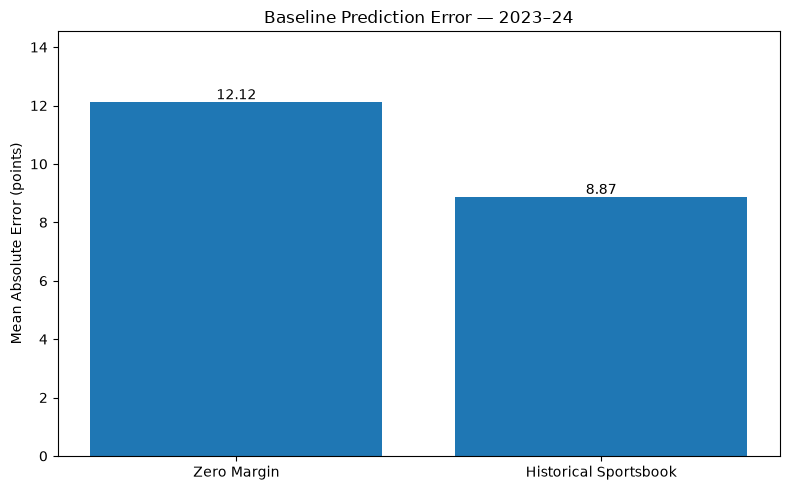

In [12]:
plt.figure(figsize=(8, 5))

bars = plt.bar(baseline_results["Model"], baseline_results["MAE"])

# Display MAE above each bar.
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.1,
        f"{height:.2f}",
        ha="center"
    )

plt.ylabel("Mean Absolute Error (points)")
plt.title("Baseline Prediction Error — 2023–24")
plt.ylim(0, baseline_results["MAE"].max() * 1.2)
plt.tight_layout()
plt.show()

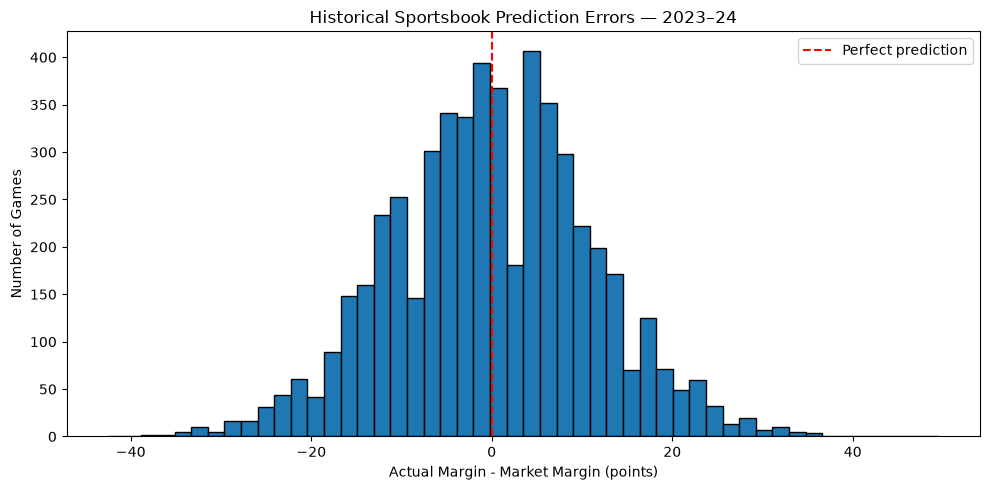

Mean signed error: -0.019
Error standard deviation: 11.196


In [13]:
# Positive error means the home team outperformed
# the sportsbook's expected margin.
market_errors = y_market - market_predictions

plt.figure(figsize=(10, 5))

plt.hist(market_errors, bins=50, edgecolor="black")

plt.axvline(0, color="red", linestyle="--", label="Perfect prediction")

plt.xlabel("Actual Margin - Market Margin (points)")
plt.ylabel("Number of Games")
plt.title("Historical Sportsbook Prediction Errors — 2023–24")
plt.legend()
plt.tight_layout()
plt.show()

print("Mean signed error:", round(market_errors.mean(), 3))
print("Error standard deviation:", round(market_errors.std(), 3))

# Ridge Regression Test

In [14]:
# Prep data for Ridge
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# Pipeline applies transformations in sequence.
ridge_pipeline = Pipeline([
    # Replace missing values using training-set medians.
    ("imputer", SimpleImputer(strategy="median")),
    # Standardize each feature using training-set statistics.
    ("scaler", StandardScaler()),
    # Ridge regression model.
    ("ridge", Ridge(alpha=1.0))
])

# Fit preprocessing and Ridge using training data only.
ridge_pipeline.fit(X_train, y_train)

# Predict the 2023-24 validation season.
ridge_predictions = ridge_pipeline.predict(X_val)

In [15]:
# Test Ridge MAE against Sportsbook baseline
from sklearn.metrics import mean_absolute_error, mean_squared_error

ridge_mae = mean_absolute_error(y_val, ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_val, ridge_predictions))

# Evaluate Ridge on the same games as the sportsbook.
ridge_market_mae = mean_absolute_error(
    y_val.loc[market_mask],
    ridge_predictions[market_mask.to_numpy()]
)

print(f"Ridge MAE (all games):     {ridge_mae:.3f}")
print(f"Ridge RMSE (all games):    {ridge_rmse:.3f}")
print(f"Ridge MAE (market games):  {ridge_market_mae:.3f}")
print(f"Sportsbook MAE:           {market_mae:.3f}")

Ridge MAE (all games):     9.496
Ridge RMSE (all games):    12.021
Ridge MAE (market games):  9.525
Sportsbook MAE:           8.873


In [16]:
# Try 30 alpha values from 0.01 to 10,000.
alphas = np.logspace(-2, 4, 30)

ridge_results = []

for alpha in alphas:
    # Update Ridge regularization strength.
    ridge_pipeline.set_params(ridge__alpha=alpha)
    # Fit model using historical training games.
    ridge_pipeline.fit(X_train, y_train)
    # Predict validation games.
    predictions = ridge_pipeline.predict(X_val)
    # Calculate MAE for all validation games.
    mae = mean_absolute_error(y_val, predictions)
    # Calculate MAE for games with sportsbook lines.
    market_only_mae = mean_absolute_error(y_val.loc[market_mask], predictions[market_mask.to_numpy()])

    ridge_results.append({"alpha": alpha, "MAE": mae, "Market_Games_MAE": market_only_mae})

ridge_results = pd.DataFrame(ridge_results)

display(ridge_results.sort_values("MAE").head(10))

,alpha,MAE,Market_Games_MAE
3,0.041753,9.495690,9.524899
2,0.025929,9.495695,9.524900
4,0.067234,9.495701,9.524917
1,0.016103,9.495716,9.524918
5,0.108264,9.495727,9.524950
0,0.010000,9.495745,9.524946
6,0.174333,9.495766,9.524994
7,0.280722,9.495819,9.525051
8,0.452035,9.495889,9.525123
9,0.727895,9.495977,9.525212


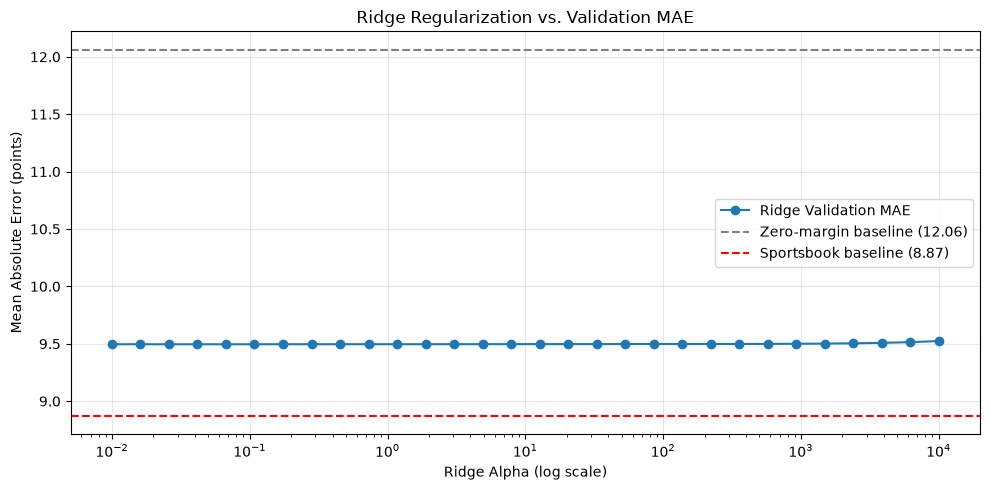

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(ridge_results["alpha"], ridge_results["MAE"], marker="o", label="Ridge Validation MAE")

plt.axhline(zero_mae, color="gray", linestyle="--", label=f"Zero-margin baseline ({zero_mae:.2f})")
plt.axhline(market_mae, color="red", linestyle="--", label=f"Sportsbook baseline ({market_mae:.2f})")

plt.xscale("log")
plt.xlabel("Ridge Alpha (log scale)")
plt.ylabel("Mean Absolute Error (points)")
plt.title("Ridge Regularization vs. Validation MAE")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Select alpha based on all validation games.
best_row = ridge_results.loc[ridge_results["MAE"].idxmin()]
best_alpha = best_row["alpha"]

print(f"Best alpha: {best_alpha:.4f}")
print(f"Best validation MAE: {best_row['MAE']:.3f}")

# Refit using the selected alpha.
ridge_pipeline.set_params(ridge__alpha=best_alpha)
ridge_pipeline.fit(X_train, y_train)

# Save predictions for later comparisons.
ridge_predictions = ridge_pipeline.predict(X_val)

print(
    "Market-games MAE:",
    round(mean_absolute_error(y_val.loc[market_mask], ridge_predictions[market_mask.to_numpy()]), 3)
)

Best alpha: 0.0418
Best validation MAE: 9.496
Market-games MAE: 9.525


In [19]:
# Extract fitted Ridge model.
ridge_model = ridge_pipeline.named_steps["ridge"]

# Pair each coefficient with its original feature name.
ridge_coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": ridge_model.coef_
})

# Rank by absolute coefficient magnitude.
ridge_coefficients["Abs_Coefficient"] = (ridge_coefficients["Coefficient"].abs())

ridge_coefficients = ridge_coefficients.sort_values("Abs_Coefficient", ascending=False)

display(ridge_coefficients.head(20))

,Feature,Coefficient,Abs_Coefficient
111,diff_last5_sos_win,-31.210176,31.210176
129,diff_last5_win,-30.110034,30.110034
108,diff_avg_sos_win,29.399549,29.399549
109,home_last5_sos_win,26.872832,26.872832
110,away_last5_sos_win,-26.851525,26.851525
107,away_avg_sos_win,24.108749,24.108749
106,home_avg_sos_win,-24.053987,24.053987
126,diff_avg_win,23.593199,23.593199
63,diff_last5_fg3_pct,-23.022862,23.022862
128,away_last5_win,-22.440308,22.440308


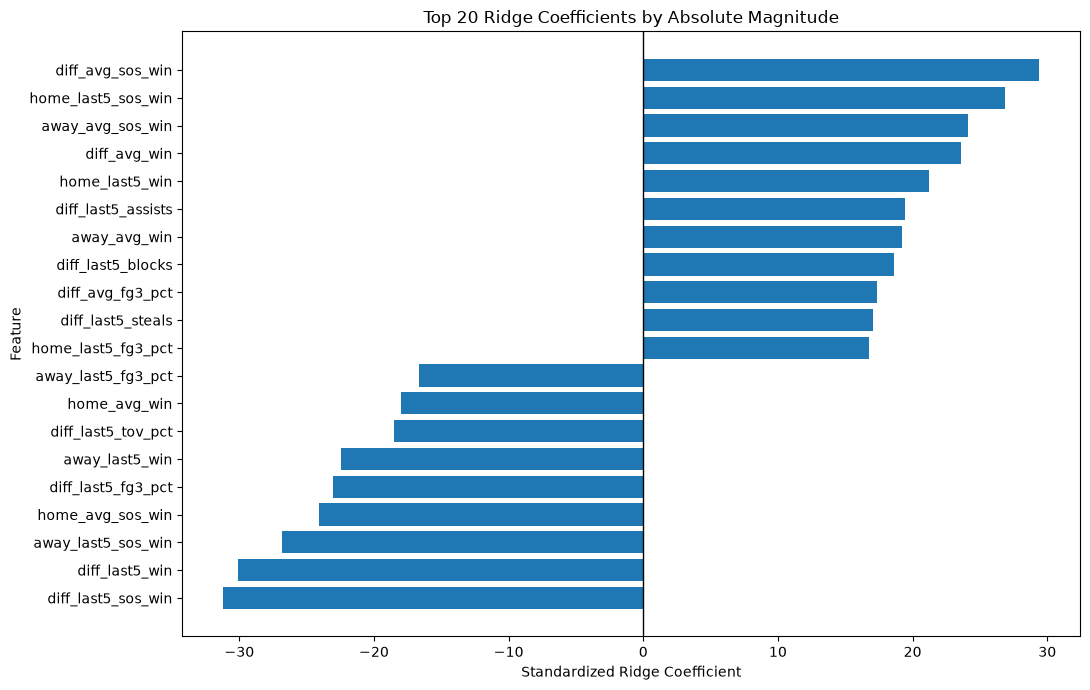

In [ ]:
top_20 = ridge_coefficients.head(20).sort_values("Coefficient")

plt.figure(figsize=(11, 7))

plt.barh(top_20["Feature"], top_20["Coefficient"])

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Standardized Ridge Coefficient")
plt.ylabel("Feature")
plt.title("Top 20 Ridge Coefficients by Absolute Magnitude")
plt.tight_layout()
plt.show()

In [21]:
# Compare model complexity at different alpha values.
alpha_check = [0.0418, 1, 10, 100, 1000, 10000]

diagnostic_results = []

for alpha in alpha_check:

    ridge_pipeline.set_params(ridge__alpha=alpha)
    ridge_pipeline.fit(X_train, y_train)

    predictions = ridge_pipeline.predict(X_val)
    coefficients = ridge_pipeline.named_steps["ridge"].coef_

    diagnostic_results.append({
        "Alpha": alpha,
        "Validation MAE": mean_absolute_error(y_val, predictions),
        "Largest |Coefficient|": np.max(np.abs(coefficients)),
        "Coefficient L2 Norm": np.linalg.norm(coefficients)
    })

diagnostic_df = pd.DataFrame(diagnostic_results)

display(diagnostic_df.round(3))

,Alpha,Validation MAE,Largest |Coefficient|,Coefficient L2 Norm
0,0.042,9.496,31.193,129.168
1,1.000,9.496,7.269,25.293
2,10.000,9.497,2.274,8.775
3,100.000,9.498,1.631,5.771
4,1000.000,9.500,1.269,4.135
5,10000.000,9.524,0.880,2.824


# Lasso Regression Test

In [22]:
# Create Lasso Pipeline
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

lasso_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lasso", Lasso(alpha=0.1, max_iter=20000, tol=1e-4))
])

# Fit using training seasons only.
lasso_pipeline.fit(X_train, y_train)

# Initial prediction
lasso_predictions = lasso_pipeline.predict(X_val)

print("Initial Lasso MAE:", mean_absolute_error(y_val, lasso_predictions))

Initial Lasso MAE: 9.514141349471469


In [23]:
# Lasso uses a different alpha scale than Ridge.
lasso_alphas = np.logspace(-3, 1, 25)

lasso_results = []

for alpha in lasso_alphas:
    lasso_pipeline.set_params(lasso__alpha=alpha)
    # Train the model.
    lasso_pipeline.fit(X_train, y_train)
    # Predict validation games.
    predictions = lasso_pipeline.predict(X_val)
    # Extract fitted coefficients.
    coefficients = lasso_pipeline.named_steps["lasso"].coef_
    # Count selected features.
    # A tiny tolerance avoids treating numerical noise as important.
    selected_count = np.sum(np.abs(coefficients) > 1e-6)
    # Measure prediction error.
    mae = mean_absolute_error(y_val, predictions)
    market_only_mae = mean_absolute_error(y_val.loc[market_mask], predictions[market_mask.to_numpy()])

    lasso_results.append({
        "alpha": alpha,
        "features": selected_count,
        "MAE": mae,
        "Market_Games_MAE": market_only_mae
    })

lasso_results = pd.DataFrame(lasso_results)

display(lasso_results.round(4))

,alpha,features,MAE,Market_Games_MAE
0,0.0010,220,9.4976,9.5267
1,0.0015,186,9.4982,9.5274
2,0.0022,168,9.4987,9.5280
3,0.0032,147,9.4993,9.5286
4,0.0046,136,9.4999,9.5291
5,0.0068,126,9.4997,9.5289
6,0.0100,123,9.4999,9.5290
7,0.0147,116,9.5006,9.5296
8,0.0215,68,9.5015,9.5304
9,0.0316,61,9.5020,9.5305


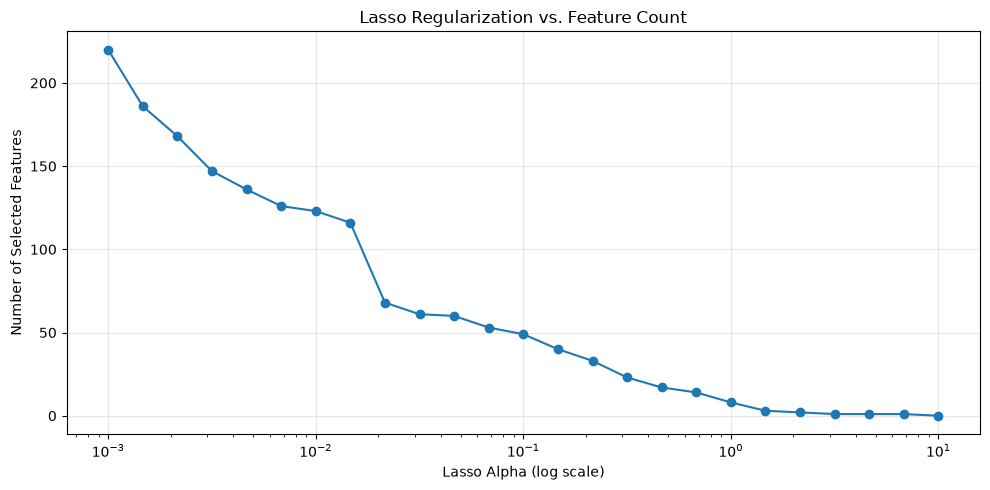

In [ ]:
# Plot alpha value vs feature count
plt.figure(figsize=(10, 5))

plt.plot(lasso_results["alpha"], lasso_results["features"], marker="o")

plt.xscale("log")

plt.xlabel("Lasso Alpha (log scale)")
plt.ylabel("Number of Selected Features")
plt.title("Lasso Regularization vs. Feature Count")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

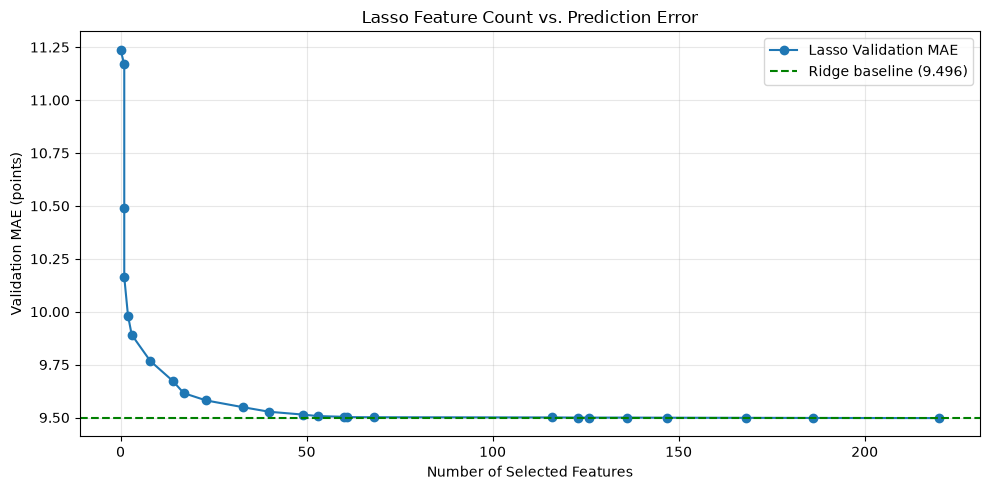

In [25]:
# Plot feature count vs MAE
plt.figure(figsize=(10, 5))

plt.plot( lasso_results["features"],lasso_results["MAE"],marker="o",label="Lasso Validation MAE")

# Compare against our best Ridge model.
plt.axhline(9.496, color="green", linestyle="--", label="Ridge baseline (9.496)")

plt.xlabel("Number of Selected Features")
plt.ylabel("Validation MAE (points)")
plt.title("Lasso Feature Count vs. Prediction Error")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# Find the smallest model within an acceptable MAE increase
# Lowest validation MAE achieved by Lasso.
best_lasso_mae = lasso_results["MAE"].min()

# Maximum acceptable increase in MAE.
mae_tolerance = 0.10

# Keep models that perform within 0.10 MAE of the best.
acceptable_models = lasso_results[lasso_results["MAE"] <= best_lasso_mae + mae_tolerance]

# Choose the smallest qualifying model.
selected_row = acceptable_models.sort_values(["features", "MAE"]).iloc[0]

selected_alpha = selected_row["alpha"]

print(f"Best Lasso MAE: {best_lasso_mae:.3f}")
print(f"Selected alpha: {selected_alpha:.5f}")
print(f"Selected features: {int(selected_row['features'])}")
print(f"Selected model MAE: {selected_row['MAE']:.3f}")

Best Lasso MAE: 9.498
Selected alpha: 0.31623
Selected features: 23
Selected model MAE: 9.581


In [27]:
# Extract the selected feature names
# Refit Lasso using the chosen alpha.
lasso_pipeline.set_params(lasso__alpha=selected_alpha)
lasso_pipeline.fit(X_train, y_train)

# Get coefficients from the final selected Lasso model.
lasso_coefficients = lasso_pipeline.named_steps["lasso"].coef_

# Select features with nonzero coefficients.
selected_mask = np.abs(lasso_coefficients) > 1e-6

lasso_selected_features = X_train.columns[selected_mask].tolist()

print("Number of selected features:", len(lasso_selected_features))

# Display selected features and coefficients.
selected_feature_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lasso_coefficients
})

selected_feature_df = selected_feature_df[selected_feature_df["Feature"].isin(lasso_selected_features)].copy()

selected_feature_df["Abs_Coefficient"] = (selected_feature_df["Coefficient"].abs())

selected_feature_df = selected_feature_df.sort_values("Abs_Coefficient", ascending=False)

display(selected_feature_df.head(25))

Number of selected features: 23


,Feature,Coefficient,Abs_Coefficient
18,diff_avg_margin,5.460015,5.460015
114,diff_avg_sos_margin,1.212700,1.212700
120,diff_avg_sor,0.896737,0.896737
0,neutral_site,-0.768692,0.768692
1,conference_game,-0.559428,0.559428
123,diff_last5_sor,0.527267,0.527267
264,missing_home_rest_days,0.439446,0.439446
84,diff_avg_assists,0.324136,0.324136
140,missing_diff_avg_points_for,0.261308,0.261308
139,missing_away_avg_points_for,0.254257,0.254257


In [28]:
# Compare Ridge with and without lasso featrue selection
# Create a new Ridge pipeline using only Lasso-selected features.
ridge_selected_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=100))
])

ridge_selected_pipeline.fit(X_train[lasso_selected_features],y_train)

selected_ridge_predictions = ridge_selected_pipeline.predict(X_val[lasso_selected_features])

selected_ridge_mae = mean_absolute_error(y_val,selected_ridge_predictions)

print(f"Full Ridge MAE:       {9.496:.3f}")
print(f"Selected Ridge MAE:   {selected_ridge_mae:.3f}")
print(f"Features retained:    {len(lasso_selected_features)}")

Full Ridge MAE:       9.496
Selected Ridge MAE:   9.520
Features retained:    23


In [29]:
from sklearn.base import clone

ridge_subset_results = []

# Test each Lasso alpha from our earlier experiment.
for alpha in lasso_alphas:

    # Select features using Lasso.
    lasso_model = clone(lasso_pipeline)
    lasso_model.set_params(lasso__alpha=alpha)
    lasso_model.fit(X_train, y_train)

    coefficients = lasso_model.named_steps["lasso"].coef_

    selected = X_train.columns[
        np.abs(coefficients) > 1e-6
    ].tolist()

    if len(selected) == 0:
        continue

    # Train Ridge using only those selected features.
    ridge_model = clone(ridge_selected_pipeline)

    ridge_model.fit(
        X_train[selected],
        y_train
    )

    predictions = ridge_model.predict(X_val[selected])

    ridge_subset_results.append({
        "Lasso Alpha": alpha,
        "Features": len(selected),
        "Ridge MAE": mean_absolute_error(
            y_val, predictions
        )
    })

ridge_subset_results = pd.DataFrame(ridge_subset_results)

display(
    ridge_subset_results.sort_values("Features")
)

,Lasso Alpha,Features,Ridge MAE
23,6.812921,1,9.870301
21,3.162278,1,9.870301
22,4.641589,1,9.870301
20,2.154435,2,9.808266
19,1.467799,3,9.730601
18,1.000000,8,9.631037
17,0.681292,14,9.555114
16,0.464159,17,9.555446
15,0.316228,23,9.519649
14,0.215443,33,9.504722


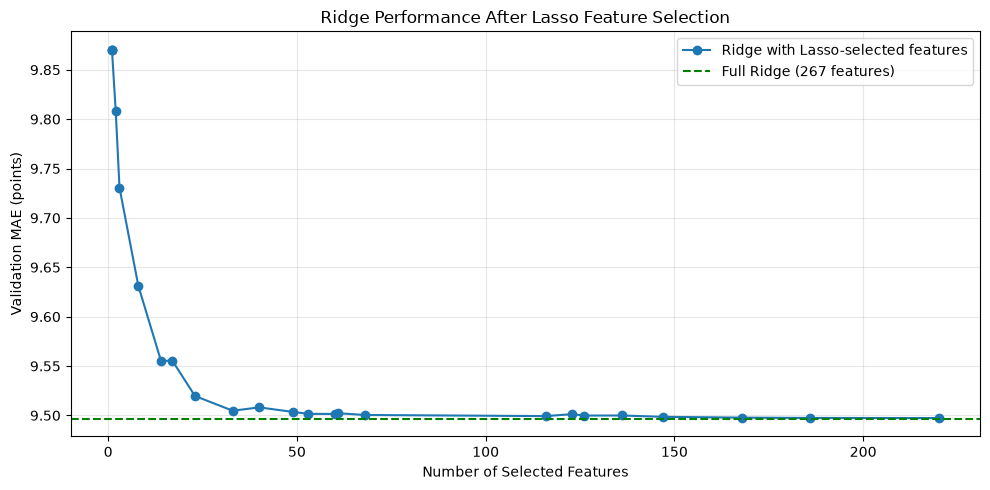

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(
    ridge_subset_results["Features"],
    ridge_subset_results["Ridge MAE"],
    marker="o",
    label="Ridge with Lasso-selected features"
)

plt.axhline(
    9.496,
    color="green",
    linestyle="--",
    label="Full Ridge (267 features)"
)

plt.xlabel("Number of Selected Features")
plt.ylabel("Validation MAE (points)")
plt.title("Ridge Performance After Lasso Feature Selection")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Unsupervised Learning Test PCA

In [31]:
# Prepare the Continous Features
# PCA will operate on the continuous basketball statistics.
pca_features = raw_features.copy()

X_train_pca = X_train[pca_features].copy()
X_val_pca = X_val[pca_features].copy()

print("PCA input features:", len(pca_features))
print("Training shape:", X_train_pca.shape)
print("Validation shape:", X_val_pca.shape)

PCA input features: 138
Training shape: (37041, 138)
Validation shape: (5726, 138)


In [32]:
# Impute and Standardize
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Fit the imputer using training data only.
pca_imputer = SimpleImputer(strategy="median")

X_train_imputed = pca_imputer.fit_transform(X_train_pca)
X_val_imputed = pca_imputer.transform(X_val_pca)

# Fit the scaler using training data only.
pca_scaler = StandardScaler()

X_train_scaled = pca_scaler.fit_transform(X_train_imputed)
X_val_scaled = pca_scaler.transform(X_val_imputed)

print("Scaled training shape:", X_train_scaled.shape)

Scaled training shape: (37041, 138)


In [33]:
# Fit PCA and examine explained variance
from sklearn.decomposition import PCA

pca = PCA()

# PCA learns directions of maximum variance
# from the training data only.
pca.fit(X_train_scaled)

explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

print("Total components:", len(explained_variance))

for threshold in [0.80, 0.90, 0.95, 0.99]:
    n = np.searchsorted(cumulative_variance, threshold) + 1
    print(f"{threshold:.0%} variance: {n} components")

Total components: 138
80% variance: 19 components
90% variance: 31 components
95% variance: 43 components
99% variance: 67 components


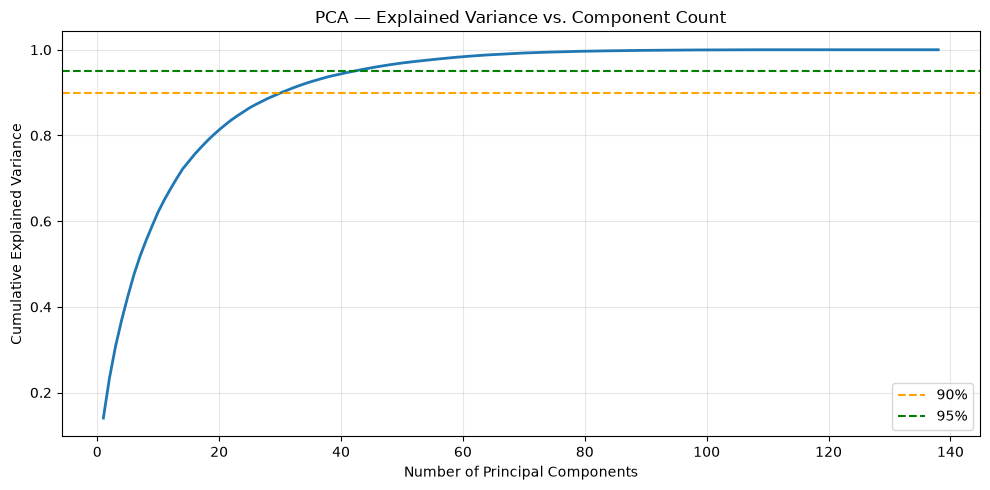

In [34]:
# Plot cumulatice expalined variance
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2
)

plt.axhline(0.90, color="orange", linestyle="--", label="90%")
plt.axhline(0.95, color="green", linestyle="--", label="95%")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA — Explained Variance vs. Component Count")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
# Inspect the first few principal components
# Each row corresponds to a principal component.
# Each column corresponds to an original feature.
loadings = pd.DataFrame(
    pca.components_,
    columns=pca_features
)

for i in range(3):
    print(f"\nPrincipal Component {i+1}")

    top_features = (
        loadings.iloc[i]
        .abs()
        .sort_values(ascending=False)
        .head(10)
        .index
    )

    display(
        loadings.loc[i, top_features]
        .sort_values(ascending=False)
    )


Principal Component 1


diff_last5_margin        0.208430
diff_avg_margin          0.207206
diff_avg_win             0.195458
diff_last5_win           0.188086
diff_avg_points_for      0.168983
diff_last5_points_for    0.164909
diff_avg_sor             0.162882
diff_last5_sor           0.161382
diff_avg_efg             0.154659
diff_avg_assists         0.146137
Name: 0, dtype: float64


Principal Component 2


away_avg_margin      0.208676
away_avg_win         0.199280
home_avg_margin      0.198417
away_last5_margin    0.192580
home_avg_win         0.189073
away_avg_sor         0.184394
home_last5_margin    0.178695
away_last5_win       0.175857
home_avg_sor         0.175464
away_last5_sor       0.172256
Name: 1, dtype: float64


Principal Component 3


diff_last5_possessions       0.266815
diff_avg_possessions         0.265355
diff_last5_pace              0.260489
diff_avg_pace                0.258999
diff_avg_points_against      0.208983
diff_last5_points_against    0.207846
away_last5_pace             -0.175198
away_last5_possessions      -0.179351
away_avg_pace               -0.190423
away_avg_possessions        -0.193585
Name: 2, dtype: float64

In [36]:
# Test PCA componants with Ridge
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

# Missing indicators are already 0/1 columns.
missing_train = X_train[missing_features].fillna(0).to_numpy()
missing_val = X_val[missing_features].fillna(0).to_numpy()

component_counts = [5, 10, 15, 20, 30, 40, 60, 80, 100, 120, 138]

pca_results = []

for n_components in component_counts:

    # Transform data into the first N principal components.
    train_components = pca.transform(X_train_scaled)[:, :n_components]
    val_components = pca.transform(X_val_scaled)[:, :n_components]

    # Combine PCA components with missing indicators.
    train_combined = np.column_stack([
        train_components,
        missing_train
    ])

    val_combined = np.column_stack([
        val_components,
        missing_val
    ])

    # Train Ridge on PCA features.
    model = Ridge(alpha=100)

    model.fit(train_combined, y_train)

    predictions = model.predict(val_combined)

    pca_results.append({
        "Components": n_components,
        "Total Features": n_components + len(missing_features),
        "Validation MAE": mean_absolute_error(y_val, predictions)
    })

pca_results = pd.DataFrame(pca_results)

display(pca_results)

,Components,Total Features,Validation MAE
0,5,134,9.863118
1,10,139,9.770268
2,15,144,9.719541
3,20,149,9.712179
4,30,159,9.574309
5,40,169,9.558917
6,60,189,9.512945
7,80,209,9.500900
8,100,229,9.499002
9,120,249,9.498395


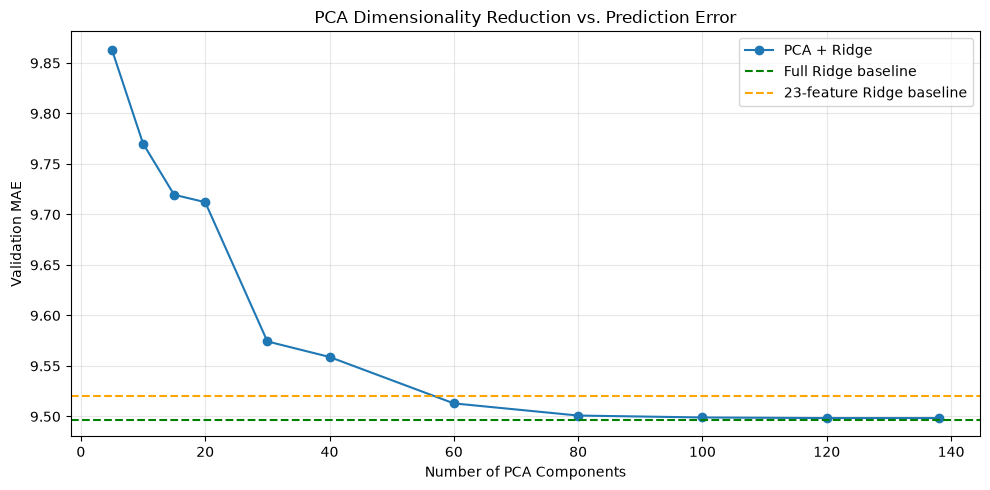

In [37]:
# Plot PCA preformance
plt.figure(figsize=(10, 5))

plt.plot(
    pca_results["Components"],
    pca_results["Validation MAE"],
    marker="o",
    label="PCA + Ridge"
)

plt.axhline(
    9.496,
    color="green",
    linestyle="--",
    label="Full Ridge baseline"
)

plt.axhline(
    9.520,
    color="orange",
    linestyle="--",
    label="23-feature Ridge baseline"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Validation MAE")
plt.title("PCA Dimensionality Reduction vs. Prediction Error")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Unsupervised Learning Test K-Means Clustering

In [38]:
# Basketball statistics used to describe team style.
style_stats = [
    "avg_off_eff",
    "avg_def_eff",
    "avg_pace",
    "avg_efg",
    "avg_oreb_pct",
    "avg_tov_pct",
    "avg_ft_rate"
]

# Corresponding home and away features.
home_style_cols = ["home_" + s for s in style_stats]
away_style_cols = ["away_" + s for s in style_stats]

# Verify that every feature exists.
assert all(c in train_df.columns for c in home_style_cols)
assert all(c in train_df.columns for c in away_style_cols)

print("Style features:", style_stats)

Style features: ['avg_off_eff', 'avg_def_eff', 'avg_pace', 'avg_efg', 'avg_oreb_pct', 'avg_tov_pct', 'avg_ft_rate']


In [39]:
def create_team_profiles(df):
    # Extract home-team statistics.
    home = df[home_style_cols].copy()
    home.columns = style_stats

    # Extract away-team statistics.
    away = df[away_style_cols].copy()
    away.columns = style_stats

    # Combine both into one dataset.
    profiles = pd.concat(
        [home, away],
        ignore_index=True
    )

    return profiles

train_profiles = create_team_profiles(train_df)
val_profiles = create_team_profiles(val_df)

print("Training profiles:", train_profiles.shape)
print("Validation profiles:", val_profiles.shape)

Training profiles: (74082, 7)
Validation profiles: (11452, 7)


In [40]:
# Impute and Standardize
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Fit using training profiles only.
cluster_imputer = SimpleImputer(strategy="median")

train_profiles_imputed = cluster_imputer.fit_transform(
    train_profiles
)

val_profiles_imputed = cluster_imputer.transform(
    val_profiles
)

cluster_scaler = StandardScaler()

train_profiles_scaled = cluster_scaler.fit_transform(
    train_profiles_imputed
)

val_profiles_scaled = cluster_scaler.transform(
    val_profiles_imputed
)

print("Scaled profiles:", train_profiles_scaled.shape)

Scaled profiles: (74082, 7)


In [41]:
# Determin number of clusters
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)

cluster_results = []

# Fixed subset for silhouette evaluation.
rng = np.random.default_rng(42)

sample_size = min(3000, len(train_profiles_scaled))

sample_idx = rng.choice(
    len(train_profiles_scaled),
    size=sample_size,
    replace=False
)

sample_profiles = train_profiles_scaled[sample_idx]

for k in k_values:

    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        n_init=5
    )

    model.fit(train_profiles_scaled)

    # Assign the sampled profiles to clusters.
    sample_labels = model.predict(sample_profiles)

    silhouette = silhouette_score(
        sample_profiles,
        sample_labels
    )

    cluster_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette
    })

cluster_results = pd.DataFrame(cluster_results)

display(cluster_results)

,K,Inertia,Silhouette
0,2,478552.557506,0.178969
1,3,436623.785352,0.125866
2,4,400332.673663,0.125742
3,5,391216.626999,0.088451
4,6,283562.171018,0.124871
5,7,269078.781145,0.121797
6,8,259670.906386,0.126509
7,9,245811.608745,0.119334
8,10,253900.226656,0.113382


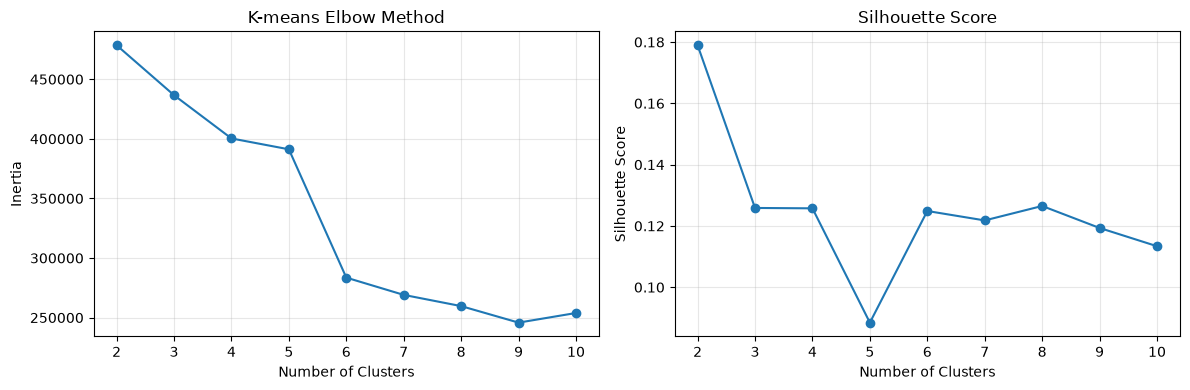

In [42]:
# Plot inertia and silhouette scores
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    cluster_results["K"],
    cluster_results["Inertia"],
    marker="o"
)

axes[0].set_title("K-means Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

axes[1].plot(
    cluster_results["K"],
    cluster_results["Silhouette"],
    marker="o"
)

axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [43]:
# Fit and interpret a clustering model
from sklearn.cluster import MiniBatchKMeans

k = 4

kmeans = MiniBatchKMeans(
    n_clusters=k,
    random_state=42,
    batch_size=2048,
    n_init=10
)

kmeans.fit(train_profiles_scaled)

train_cluster_labels = kmeans.predict(train_profiles_scaled)
val_cluster_labels = kmeans.predict(val_profiles_scaled)

print(
    "Training cluster counts:",
    np.bincount(train_cluster_labels)
)

Training cluster counts: [22588 20151 29352  1991]


In [44]:
# Convert cluster centers back to original units.
centers_original = cluster_scaler.inverse_transform(
    kmeans.cluster_centers_
)

cluster_centers_df = pd.DataFrame(
    centers_original,
    columns=style_stats
)

cluster_centers_df.index.name = "Cluster"

display(cluster_centers_df.round(3))

,avg_off_eff,avg_def_eff,avg_pace,avg_efg,avg_oreb_pct,avg_tov_pct,avg_ft_rate
Cluster,,,,,,,
0,94.759,106.658,69.383,0.465,0.264,0.201,0.308
1,106.424,99.725,70.528,0.508,0.326,0.197,0.406
2,108.168,101.410,67.561,0.528,0.284,0.182,0.310
3,133.422,132.501,66.882,0.522,0.249,0.238,0.373


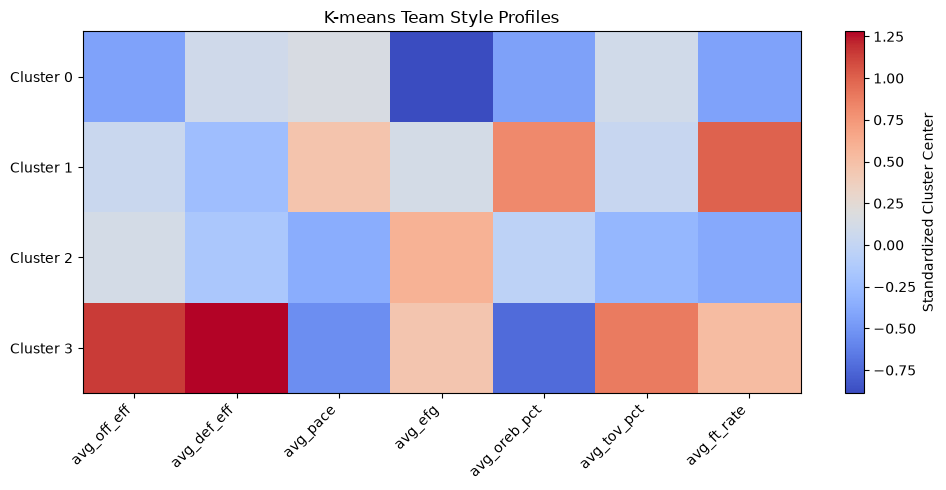

In [45]:
plt.figure(figsize=(10, 5))

plt.imshow(
    kmeans.cluster_centers_,
    cmap="coolwarm",
    aspect="auto"
)

plt.colorbar(label="Standardized Cluster Center")

plt.xticks(
    range(len(style_stats)),
    style_stats,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(k),
    [f"Cluster {i}" for i in range(k)]
)

plt.title("K-means Team Style Profiles")
plt.tight_layout()
plt.show()

In [46]:
# Does Clustering actually help Ridge
# Distance from every team profile to each cluster center.
train_distances = kmeans.transform(train_profiles_scaled)
val_distances = kmeans.transform(val_profiles_scaled)

n_train = len(train_df)
n_val = len(val_df)

# Split back into home and away team profiles.
train_home_dist = train_distances[:n_train]
train_away_dist = train_distances[n_train:]

val_home_dist = val_distances[:n_val]
val_away_dist = val_distances[n_val:]

def make_distance_features(home_dist, away_dist):
    data = {}

    for i in range(home_dist.shape[1]):
        data[f"home_cluster_dist_{i}"] = home_dist[:, i]
        data[f"away_cluster_dist_{i}"] = away_dist[:, i]

        # Relative distance to the same style.
        data[f"diff_cluster_dist_{i}"] = (
            home_dist[:, i] - away_dist[:, i]
        )

    return pd.DataFrame(data)

cluster_train_features = make_distance_features(
    train_home_dist,
    train_away_dist
)

cluster_val_features = make_distance_features(
    val_home_dist,
    val_away_dist
)

print("New cluster features:", cluster_train_features.shape[1])

New cluster features: 12


In [47]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

# Start with the original predictors.
X_train_clustered = X_train.reset_index(drop=True).copy()
X_val_clustered = X_val.reset_index(drop=True).copy()

# Append cluster-derived features.
X_train_clustered = pd.concat(
    [X_train_clustered, cluster_train_features],
    axis=1
)

X_val_clustered = pd.concat(
    [X_val_clustered, cluster_val_features],
    axis=1
)

# Ridge with original features only.
base_model = clone(ridge_pipeline)
base_model.set_params(ridge__alpha=100)

base_model.fit(X_train, y_train)

base_predictions = base_model.predict(X_val)

# Ridge with original + cluster features.
cluster_model = clone(ridge_pipeline)
cluster_model.set_params(ridge__alpha=100)

cluster_model.fit(X_train_clustered, y_train)

cluster_predictions = cluster_model.predict(X_val_clustered)

comparison = pd.DataFrame({
    "Model": [
        "Ridge without clustering",
        "Ridge with clustering"
    ],
    "Features": [
        X_train.shape[1],
        X_train_clustered.shape[1]
    ],
    "Validation MAE": [
        mean_absolute_error(y_val, base_predictions),
        mean_absolute_error(y_val, cluster_predictions)
    ]
})

display(comparison.round(4))

,Model,Features,Validation MAE
0,Ridge without clustering,267,9.4976
1,Ridge with clustering,279,9.4683


In [48]:
# Attach the cluster labels to the team profiles.
cluster_analysis = train_profiles.copy()

cluster_analysis["cluster"] = train_cluster_labels

# Add the number of previous games for each profile.
cluster_analysis["games_played"] = np.concatenate([
    train_df["home_games_played"].to_numpy(),
    train_df["away_games_played"].to_numpy()
])

# Summarize each cluster.
cluster_summary = cluster_analysis.groupby("cluster").agg(
    profiles=("cluster", "size"),
    median_games=("games_played", "median"),
    mean_games=("games_played", "mean"),
    avg_off_eff=("avg_off_eff", "mean"),
    avg_def_eff=("avg_def_eff", "mean")
)

cluster_summary["percent_of_profiles"] = (
    100 * cluster_summary["profiles"] / len(cluster_analysis)
)

display(cluster_summary.round(2))

,profiles,median_games,mean_games,avg_off_eff,avg_def_eff,percent_of_profiles
cluster,,,,,,
0,22588,13.0,13.30,94.35,106.81,30.49
1,20151,13.0,14.22,106.42,99.75,27.20
2,29352,16.0,15.75,107.99,101.70,39.62
3,1991,25.0,21.28,180.03,173.67,2.69


<Figure size 900x500 with 0 Axes>

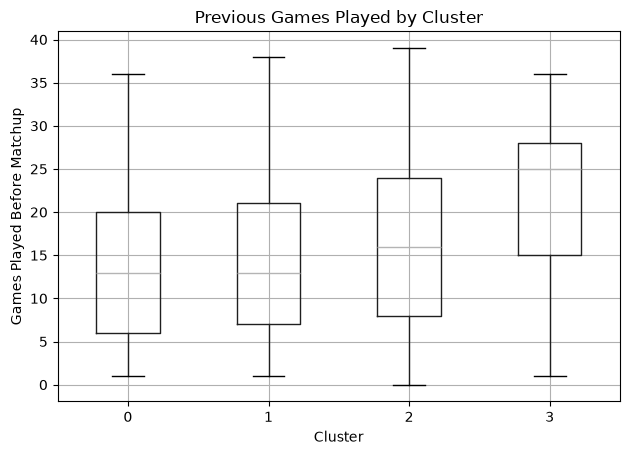

In [49]:
plt.figure(figsize=(9, 5))

cluster_analysis.boxplot(
    column="games_played",
    by="cluster"
)

plt.title("Previous Games Played by Cluster")
plt.suptitle("")
plt.xlabel("Cluster")
plt.ylabel("Games Played Before Matchup")
plt.tight_layout()
plt.show()

In [50]:
from sklearn.base import clone

k_results = []

for k in [2, 3, 4, 5, 6, 8, 10]:

    km = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=2048,
        n_init=10
    )

    km.fit(train_profiles_scaled)

    train_dist = km.transform(train_profiles_scaled)
    val_dist = km.transform(val_profiles_scaled)

    # Separate home and away observations.
    train_cluster = make_distance_features(
        train_dist[:len(train_df)],
        train_dist[len(train_df):]
    )

    val_cluster = make_distance_features(
        val_dist[:len(val_df)],
        val_dist[len(val_df):]
    )

    # Combine original features with cluster distances.
    Xtr = pd.concat([
        X_train.reset_index(drop=True),
        train_cluster
    ], axis=1)

    Xva = pd.concat([
        X_val.reset_index(drop=True),
        val_cluster
    ], axis=1)

    model = clone(ridge_pipeline)
    model.set_params(ridge__alpha=100)

    model.fit(Xtr, y_train)
    predictions = model.predict(Xva)

    k_results.append({
        "K": k,
        "Features": Xtr.shape[1],
        "Validation MAE": mean_absolute_error(
            y_val, predictions
        )
    })

k_results = pd.DataFrame(k_results)

display(k_results.round(4))

,K,Features,Validation MAE
0,2,273,9.4965
1,3,276,9.4745
2,4,279,9.4683
3,5,282,9.4621
4,6,285,9.4710
5,8,291,9.4656
6,10,297,9.4646


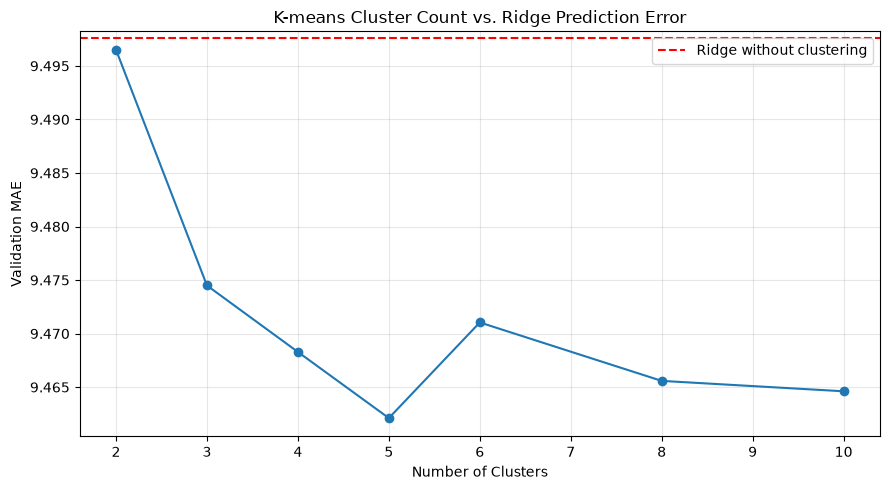

In [51]:
plt.figure(figsize=(9, 5))

plt.plot(
    k_results["K"],
    k_results["Validation MAE"],
    marker="o"
)

plt.axhline(
    9.4976,
    color="red",
    linestyle="--",
    label="Ridge without clustering"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Validation MAE")
plt.title("K-means Cluster Count vs. Ridge Prediction Error")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# XGBoost Tests

In [52]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
# Initial XGBoost model
xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train on 2016-17 through 2022-23
xgb_model.fit(X_train, y_train)

# Predict the 2023-24 validation season
xgb_predictions = xgb_model.predict(X_val)

xgb_mae = mean_absolute_error(y_val, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_val, xgb_predictions))

xgb_market_mae = mean_absolute_error(
    y_val.loc[market_mask],
    xgb_predictions[market_mask.to_numpy()]
)

print(f"XGBoost MAE (all games):    {xgb_mae:.3f}")
print(f"XGBoost RMSE (all games):   {xgb_rmse:.3f}")
print(f"XGBoost MAE (market games): {xgb_market_mae:.3f}")
print(f"Sportsbook MAE:            {market_mae:.3f}")

XGBoost MAE (all games):    9.406
XGBoost RMSE (all games):   11.859
XGBoost MAE (market games): 9.417
Sportsbook MAE:            8.873


In [53]:
model_comparison = pd.DataFrame({
    "Model": [
        "Zero Margin",
        "Sportsbook",
        "Full Ridge",
        "Lasso-selected Ridge",
        "XGBoost"
    ],
    "Validation MAE": [
        zero_mae,
        np.nan,  # Sportsbook does not cover every game
        9.496,
        9.520,
        xgb_mae
    ],
    "Market Games MAE": [
        zero_market_mae,
        market_mae,
        9.525,
        np.nan,  # Calculate separately if needed
        xgb_market_mae
    ]
})

display(model_comparison.round(3))

,Model,Validation MAE,Market Games MAE
0,Zero Margin,12.062,12.117
1,Sportsbook,NaN,8.873
2,Full Ridge,9.496,9.525
3,Lasso-selected Ridge,9.520,NaN
4,XGBoost,9.406,9.417


In [54]:
depths = [2, 3, 4, 5, 6]
n_trees = [200, 500, 800]

xgb_results = []

for depth in depths:
    for trees in n_trees:

        model = XGBRegressor(
            n_estimators=trees,
            max_depth=depth,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)

        xgb_results.append({
            "Depth": depth,
            "Trees": trees,
            "MAE": mean_absolute_error(
                y_val, predictions
            )
        })

xgb_results = pd.DataFrame(xgb_results)

display(xgb_results.sort_values("MAE"))

,Depth,Trees,MAE
7,4,500,9.385389
9,5,200,9.392402
2,2,800,9.401413
5,3,800,9.402415
6,4,200,9.403304
4,3,500,9.405616
8,4,800,9.407838
12,6,200,9.409974
10,5,500,9.418216
1,2,500,9.423917


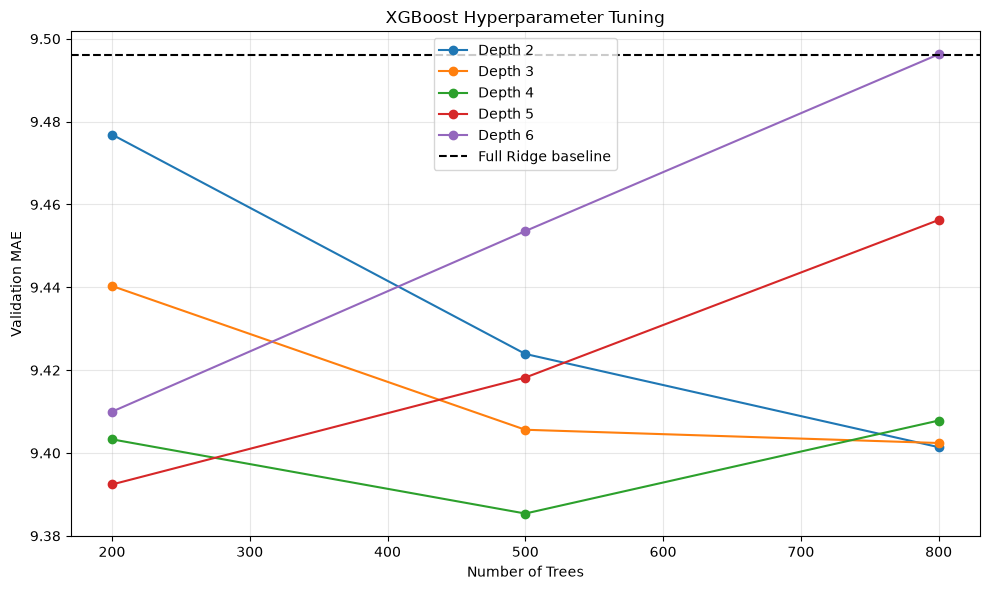

In [55]:
plt.figure(figsize=(10, 6))

for depth in depths:
    subset = xgb_results[
        xgb_results["Depth"] == depth
    ]

    plt.plot(
        subset["Trees"],
        subset["MAE"],
        marker="o",
        label=f"Depth {depth}"
    )

plt.axhline(
    9.496,
    color="black",
    linestyle="--",
    label="Full Ridge baseline"
)

plt.xlabel("Number of Trees")
plt.ylabel("Validation MAE")
plt.title("XGBoost Hyperparameter Tuning")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [56]:
best_xgb_row = xgb_results.loc[
    xgb_results["MAE"].idxmin()
]

best_depth = int(best_xgb_row["Depth"])
best_trees = int(best_xgb_row["Trees"])

print("Best depth:", best_depth)
print("Best number of trees:", best_trees)
print("Best validation MAE:", best_xgb_row["MAE"])

# Refit the best configuration
best_xgb = XGBRegressor(
    n_estimators=best_trees,
    max_depth=best_depth,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

best_xgb.fit(X_train, y_train)

best_xgb_predictions = best_xgb.predict(X_val)

Best depth: 4
Best number of trees: 500
Best validation MAE: 9.385389243592103


In [ ]:
# Gain measures the average improvement in the
# tree objective when a feature is used for a split.
booster = best_xgb.get_booster()

gain_scores = booster.get_score(
    importance_type="gain"
)

xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Gain": [
        gain_scores.get(feature, 0)
        for feature in X_train.columns
    ]
})

xgb_importance = xgb_importance.sort_values(
    "Gain",
    ascending=False
)

display(xgb_importance.head(25))

,Feature,Gain
126,diff_avg_win,51180.902344
18,diff_avg_margin,50321.218750
21,diff_last5_margin,18985.855469
120,diff_avg_sor,8518.800781
36,diff_avg_off_eff,6036.873535
114,diff_avg_sos_margin,4999.239746
108,diff_avg_sos_win,4528.932129
0,neutral_site,4500.798340
117,diff_last5_sos_margin,4244.855469
16,home_avg_margin,3721.328369


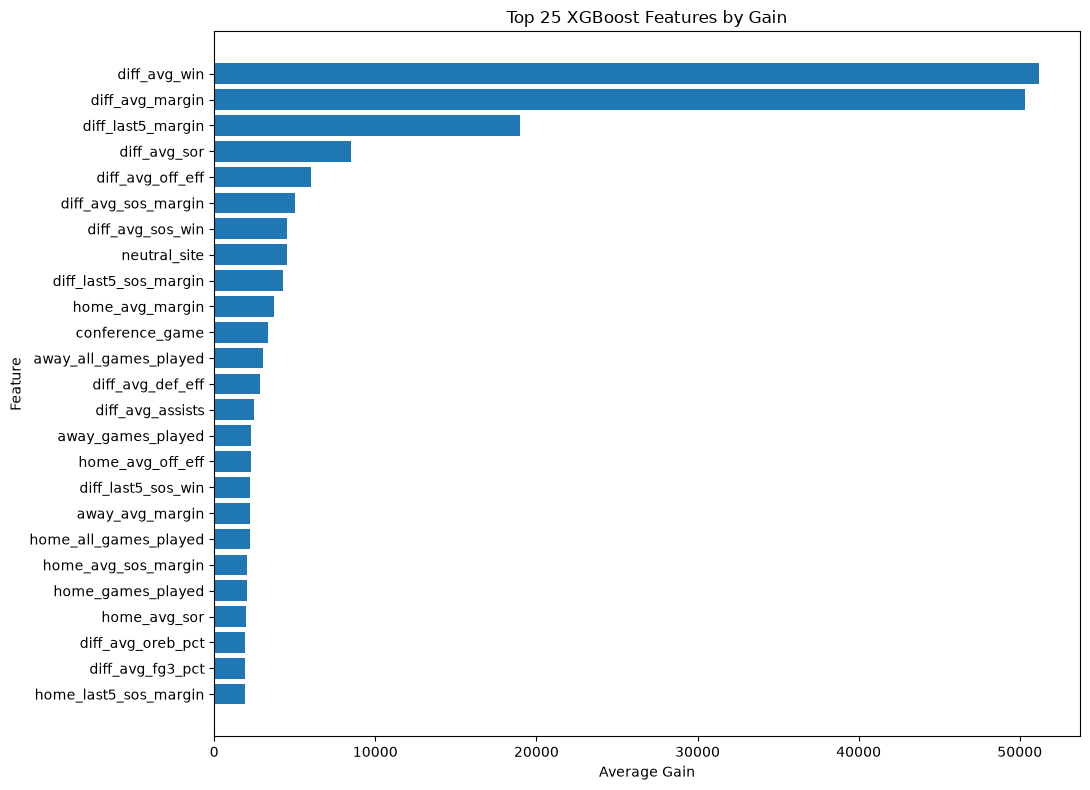

In [58]:
top_25 = xgb_importance.head(25).sort_values("Gain")

plt.figure(figsize=(11, 8))

plt.barh(
    top_25["Feature"],
    top_25["Gain"]
)

plt.xlabel("Average Gain")
plt.ylabel("Feature")
plt.title("Top 25 XGBoost Features by Gain")

plt.tight_layout()
plt.show()

In [59]:
from sklearn.base import clone

feature_counts = [10, 20, 30, 40, 50, 75, 100, 150, 200, 267]

xgb_subset_results = []

for n in feature_counts:

    selected_features = (
        xgb_importance["Feature"]
        .head(n)
        .tolist()
    )

    model = clone(best_xgb)

    model.fit(
        X_train[selected_features],
        y_train
    )

    predictions = model.predict(
        X_val[selected_features]
    )

    xgb_subset_results.append({
        "Features": n,
        "MAE": mean_absolute_error(
            y_val, predictions
        ),
        "Market MAE": mean_absolute_error(
            y_val.loc[market_mask],
            predictions[market_mask.to_numpy()]
        )
    })

xgb_subset_results = pd.DataFrame(xgb_subset_results)

display(xgb_subset_results.round(4))

,Features,MAE,Market MAE
0,10,9.4694,9.4781
1,20,9.3961,9.4128
2,30,9.3798,9.3952
3,40,9.4006,9.4151
4,50,9.3899,9.4034
5,75,9.3728,9.3882
6,100,9.3879,9.4028
7,150,9.3942,9.4056
8,200,9.4006,9.4119
9,267,9.3922,9.4028


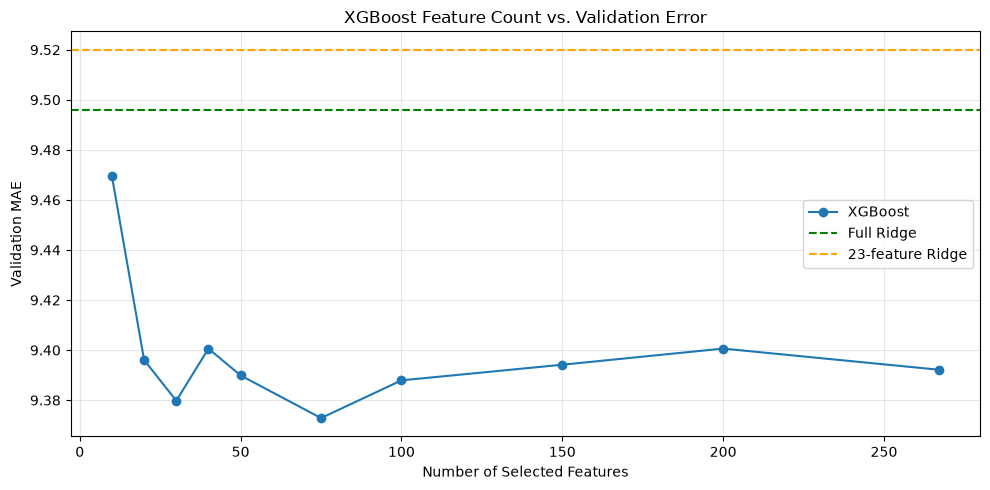

In [60]:
plt.figure(figsize=(10, 5))

plt.plot(
    xgb_subset_results["Features"],
    xgb_subset_results["MAE"],
    marker="o",
    label="XGBoost"
)

plt.axhline(
    9.496,
    color="green",
    linestyle="--",
    label="Full Ridge"
)

plt.axhline(
    9.520,
    color="orange",
    linestyle="--",
    label="23-feature Ridge"
)

plt.xlabel("Number of Selected Features")
plt.ylabel("Validation MAE")
plt.title("XGBoost Feature Count vs. Validation Error")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [61]:
best_subset_mae = xgb_subset_results["MAE"].min()

acceptable = xgb_subset_results[
    xgb_subset_results["MAE"] <= best_subset_mae + 0.10
]

selected_xgb_row = acceptable.sort_values(
    ["Features", "MAE"]
).iloc[0]

selected_xgb_count = int(
    selected_xgb_row["Features"]
)

xgb_selected_features = (
    xgb_importance["Feature"]
    .head(selected_xgb_count)
    .tolist()
)

print("Best subset MAE:", round(best_subset_mae, 3))
print("Selected feature count:", selected_xgb_count)
print("Selected subset MAE:", round(selected_xgb_row["MAE"], 3))

Best subset MAE: 9.373
Selected feature count: 10
Selected subset MAE: 9.469


In [62]:
from sklearn.cluster import MiniBatchKMeans

k = 5

kmeans_5 = MiniBatchKMeans(
    n_clusters=k,
    random_state=42,
    batch_size=2048,
    n_init=10
)

# Fit on training team profiles only.
kmeans_5.fit(train_profiles_scaled)

# Distances from each profile to the cluster centers.
train_dist = kmeans_5.transform(train_profiles_scaled)
val_dist = kmeans_5.transform(val_profiles_scaled)

# Convert back into game-level features.
cluster_train_5 = make_distance_features(
    train_dist[:len(train_df)],
    train_dist[len(train_df):]
)

cluster_val_5 = make_distance_features(
    val_dist[:len(val_df)],
    val_dist[len(val_df):]
)

print("Cluster features:", cluster_train_5.shape[1])

Cluster features: 15


In [63]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import pandas as pd

feature_counts = [20, 30, 75]

experiment_results = []
experiment_predictions = {}

for n in feature_counts:

    # Top N features from our earlier XGBoost ranking.
    selected = xgb_importance["Feature"].head(n).tolist()

    for use_clusters in [False, True]:

        # Start with the selected basketball features.
        Xtr = X_train[selected].reset_index(drop=True).copy()
        Xva = X_val[selected].reset_index(drop=True).copy()

        # Optionally append K-means features.
        if use_clusters:
            Xtr = pd.concat([Xtr, cluster_train_5], axis=1)
            Xva = pd.concat([Xva, cluster_val_5], axis=1)

        # Use our previously tuned XGBoost model.
        model = clone(best_xgb)

        model.fit(Xtr, y_train)

        predictions = model.predict(Xva)

        name = f"XGB {n}" + (" + KMeans" if use_clusters else "")

        experiment_predictions[name] = predictions

        experiment_results.append({
            "Model": name,
            "Original Features": n,
            "Cluster Features": 15 if use_clusters else 0,
            "Total Features": Xtr.shape[1],
            "Validation MAE": mean_absolute_error(
                y_val, predictions
            ),
            "Market MAE": mean_absolute_error(
                y_val.loc[market_mask],
                predictions[market_mask.to_numpy()]
            )
        })

experiment_results = pd.DataFrame(experiment_results)

display(
    experiment_results.sort_values("Validation MAE").round(4)
)

,Model,Original Features,Cluster Features,Total Features,Validation MAE,Market MAE
3,XGB 30 + KMeans,30,15,45,9.3717,9.3836
4,XGB 75,75,0,75,9.3728,9.3882
2,XGB 30,30,0,30,9.3798,9.3952
1,XGB 20 + KMeans,20,15,35,9.3936,9.4142
0,XGB 20,20,0,20,9.3961,9.4128
5,XGB 75 + KMeans,75,15,90,9.4011,9.4126


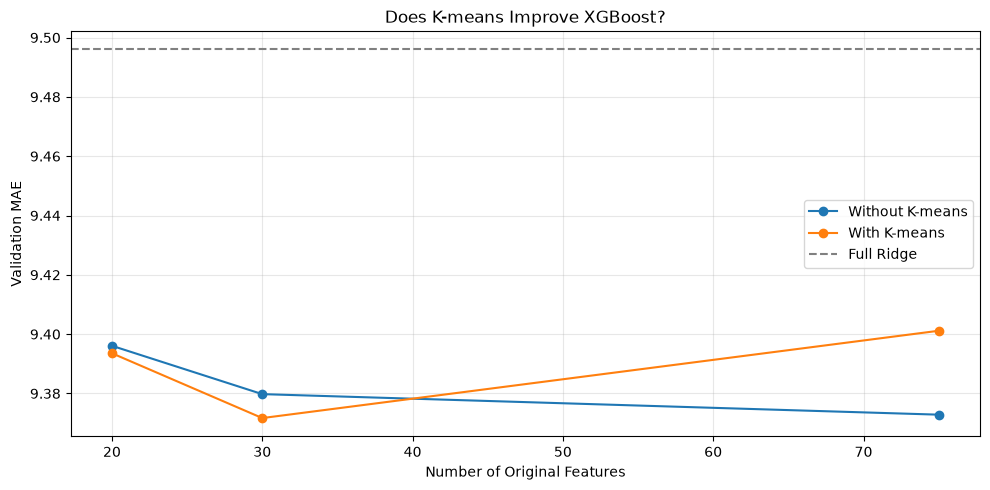

In [64]:
plt.figure(figsize=(10, 5))

for use_clusters in [False, True]:

    subset = experiment_results[
        experiment_results["Cluster Features"]
        == (15 if use_clusters else 0)
    ].sort_values("Original Features")

    plt.plot(
        subset["Original Features"],
        subset["Validation MAE"],
        marker="o",
        label="With K-means" if use_clusters else "Without K-means"
    )

plt.axhline(
    9.496,
    color="gray",
    linestyle="--",
    label="Full Ridge"
)

plt.xlabel("Number of Original Features")
plt.ylabel("Validation MAE")
plt.title("Does K-means Improve XGBoost?")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
cluster_improvements = []

for n in feature_counts:

    base = experiment_results.loc[
        experiment_results["Model"] == f"XGB {n}",
        "Validation MAE"
    ].iloc[0]

    clustered = experiment_results.loc[
        experiment_results["Model"] == f"XGB {n} + KMeans",
        "Validation MAE"
    ].iloc[0]

    cluster_improvements.append({
        "Features": n,
        "Without K-means": base,
        "With K-means": clustered,
        "MAE Improvement": base - clustered
    })

cluster_improvements = pd.DataFrame(cluster_improvements)

display(cluster_improvements.round(4))

,Features,Without K-means,With K-means,MAE Improvement
0,20,9.3961,9.3936,0.0025
1,30,9.3798,9.3717,0.0081
2,75,9.3728,9.4011,-0.0283


In [66]:
import numpy as np

rng = np.random.default_rng(42)

def paired_mae_bootstrap(y_true, pred_a, pred_b, n_boot=2000):
    """
    Estimate the MAE improvement from model A to model B.

    Positive improvement means model B is better.
    """
    y_true = np.asarray(y_true)
    pred_a = np.asarray(pred_a)
    pred_b = np.asarray(pred_b)

    # Per-game difference in absolute errors.
    improvement = (
        np.abs(y_true - pred_a)
        - np.abs(y_true - pred_b)
    )

    boot_means = []

    for _ in range(n_boot):
        indices = rng.integers(
            0, len(improvement), len(improvement)
        )

        boot_means.append(improvement[indices].mean())

    return {
        "Mean Improvement": improvement.mean(),
        "CI Lower": np.percentile(boot_means, 2.5),
        "CI Upper": np.percentile(boot_means, 97.5)
    }


bootstrap_results = []

for n in feature_counts:

    base_name = f"XGB {n}"
    cluster_name = f"XGB {n} + KMeans"

    result = paired_mae_bootstrap(
        y_val,
        experiment_predictions[base_name],
        experiment_predictions[cluster_name]
    )

    bootstrap_results.append({
        "Features": n,
        **result
    })

bootstrap_results = pd.DataFrame(bootstrap_results)

display(bootstrap_results.round(4))

,Features,Mean Improvement,CI Lower,CI Upper
0,20,0.0025,-0.0279,0.0331
1,30,0.0081,-0.0209,0.0370
2,75,-0.0283,-0.0562,-0.0008


In [67]:
best_mae = experiment_results["Validation MAE"].min()

# Keep models within 0.03 points of the best.
candidate_models = experiment_results[
    experiment_results["Validation MAE"] <= best_mae + 0.03
].copy()

display(
    candidate_models.sort_values(
        ["Total Features", "Validation MAE"]
    ).round(4)
)

,Model,Original Features,Cluster Features,Total Features,Validation MAE,Market MAE
0,XGB 20,20,0,20,9.3961,9.4128
2,XGB 30,30,0,30,9.3798,9.3952
1,XGB 20 + KMeans,20,15,35,9.3936,9.4142
3,XGB 30 + KMeans,30,15,45,9.3717,9.3836
4,XGB 75,75,0,75,9.3728,9.3882
5,XGB 75 + KMeans,75,15,90,9.4011,9.4126


# Walk forward tests

In [68]:
import time
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor

# Only development seasons: 2016-17 through 2023-24.
season_data = {
    year: load_season(year)
    for year in range(2017, 2025)
}

folds = [
    (list(range(2017, 2022)), 2022),
    (list(range(2017, 2023)), 2023),
    (list(range(2017, 2024)), 2024)
]

In [69]:
def run_walk_forward_fold(train_years, val_year):
    start = time.perf_counter()

    # Combine only seasons before the validation year.
    train = pd.concat(
        [season_data[y] for y in train_years],
        ignore_index=True
    )
    val = season_data[val_year]

    Xtr = train[feature_cols]
    ytr = train[target_col]
    Xva = val[feature_cols]
    yva = val[target_col]

    results = []

    # --------------------------------------------------
    # 1. Lasso feature selection
    # --------------------------------------------------
    lasso = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("lasso", Lasso(
            alpha=0.31623,
            max_iter=20000
        ))
    ])

    lasso.fit(Xtr, ytr)

    selected_mask = (
        np.abs(lasso.named_steps["lasso"].coef_) > 1e-6
    )

    selected_linear = Xtr.columns[selected_mask].tolist()

    # Fit Ridge using the selected features.
    ridge = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=100))
    ])

    ridge.fit(Xtr[selected_linear], ytr)
    ridge_predictions = ridge.predict(Xva[selected_linear])

    results.append({
        "Model": "Ridge + Lasso",
        "Features": len(selected_linear),
        "MAE": mean_absolute_error(yva, ridge_predictions)
    })

    # --------------------------------------------------
    # 2. XGBoost feature ranking
    # --------------------------------------------------
    xgb_params = dict(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
        importance_type="gain"
    )

    # Train a full model to rank the features.
    xgb_full = XGBRegressor(**xgb_params)
    xgb_full.fit(Xtr, ytr)

    importance = pd.Series(
        xgb_full.feature_importances_,
        index=Xtr.columns
    ).sort_values(ascending=False)

    # --------------------------------------------------
    # 3. Test 30 and 75 selected XGBoost features
    # --------------------------------------------------
    for n in [30, 75]:
        selected = importance.head(n).index.tolist()

        model = XGBRegressor(**xgb_params)

        model.fit(Xtr[selected], ytr)
        predictions = model.predict(Xva[selected])

        results.append({
            "Model": f"XGBoost {n}",
            "Features": n,
            "MAE": mean_absolute_error(yva, predictions)
        })

    elapsed = time.perf_counter() - start

    print(
        f"Validation season {val_year}: "
        f"completed in {elapsed:.1f} seconds"
    )

    return pd.DataFrame(results)

In [70]:
first_train_years, first_val_year = folds[0]

first_result = run_walk_forward_fold(
    first_train_years,
    first_val_year
)

display(first_result)

Validation season 2022: completed in 57.0 seconds


,Model,Features,MAE
0,Ridge + Lasso,24,9.185682
1,XGBoost 30,30,9.135038
2,XGBoost 75,75,9.148862


In [71]:
all_results = []

# Include the fold we already completed.
first_result["Validation Season"] = folds[0][1]
all_results.append(first_result)

# Run remaining folds.
for train_years, val_year in folds[1:]:
    result = run_walk_forward_fold(
        train_years,
        val_year
    )

    result["Validation Season"] = val_year
    all_results.append(result)

walk_forward_results = pd.concat(
    all_results,
    ignore_index=True
)

display(walk_forward_results)

Validation season 2023: completed in 62.7 seconds
Validation season 2024: completed in 49.6 seconds


,Model,Features,MAE,Validation Season
0,Ridge + Lasso,24,9.185682,2022
1,XGBoost 30,30,9.135038,2022
2,XGBoost 75,75,9.148862,2022
3,Ridge + Lasso,27,9.386120,2023
4,XGBoost 30,30,9.289919,2023
5,XGBoost 75,75,9.271384,2023
6,Ridge + Lasso,23,9.519649,2024
7,XGBoost 30,30,9.379773,2024
8,XGBoost 75,75,9.372848,2024


In [72]:
summary = (
    walk_forward_results
    .groupby("Model")
    .agg(
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_Features=("Features", "mean")
    )
    .sort_values("Mean_MAE")
)

display(summary.round(3))

,Mean_MAE,Std_MAE,Mean_Features
Model,,,
XGBoost 75,9.264,0.112,75.000
XGBoost 30,9.268,0.124,30.000
Ridge + Lasso,9.364,0.168,24.667


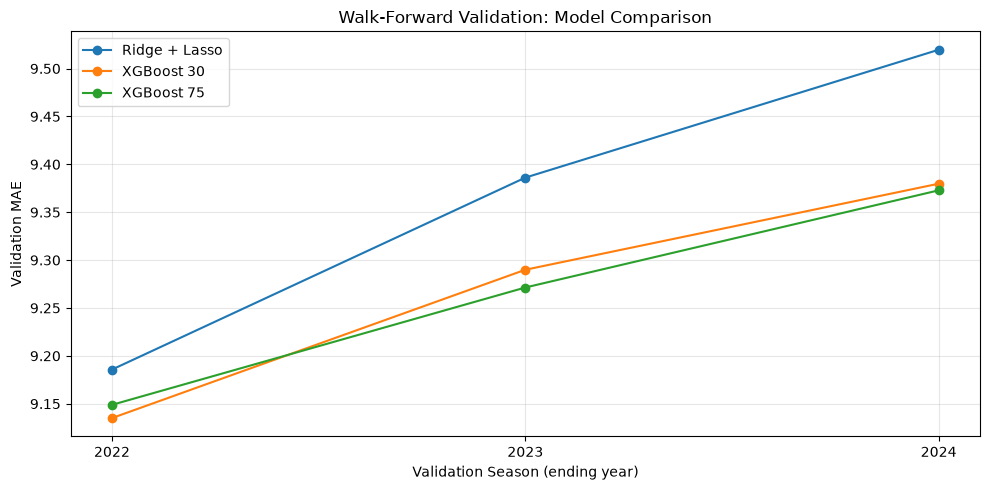

In [73]:
plt.figure(figsize=(10, 5))

for model_name, group in walk_forward_results.groupby("Model"):
    group = group.sort_values("Validation Season")

    plt.plot(
        group["Validation Season"],
        group["MAE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Validation Season (ending year)")
plt.ylabel("Validation MAE")
plt.title("Walk-Forward Validation: Model Comparison")

plt.xticks([2022, 2023, 2024])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Is the Market Error Random (Predict Sportsbook mistakes)

In [74]:
# Use only games with available sportsbook lines.
market_train = train_df[
    train_df["market_home_margin"].notna()
].copy()

market_val = val_df[
    val_df["market_home_margin"].notna()
].copy()

# Residual = actual margin minus market expectation.
market_train["market_residual"] = (
    market_train[target_col]
    - market_train["market_home_margin"]
)

market_val["market_residual"] = (
    market_val[target_col]
    - market_val["market_home_margin"]
)

print("Training games:", len(market_train))
print("Validation games:", len(market_val))

Training games: 33794
Validation games: 5304


In [75]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

residual_features = xgb_selected_features[:30]

residual_model = clone(best_xgb)

residual_model.fit(
    market_train[residual_features],
    market_train["market_residual"]
)

predicted_residuals = residual_model.predict(
    market_val[residual_features]
)

# Correct the market prediction using the predicted residual.
corrected_market = (
    market_val["market_home_margin"].to_numpy()
    + predicted_residuals
)

actual = market_val[target_col].to_numpy()
original_market = market_val["market_home_margin"].to_numpy()

print(
    "Original market MAE:",
    mean_absolute_error(actual, original_market)
)

print(
    "Residual-corrected MAE:",
    mean_absolute_error(actual, corrected_market)
)

Original market MAE: 8.872926093514328
Residual-corrected MAE: 8.891820354926756


In [76]:
analysis = market_val.copy()

analysis["absolute_error"] = (
    analysis[target_col] - analysis["market_home_margin"]
).abs()

# Group games by the magnitude of the market's expected margin.
analysis["spread_group"] = pd.cut(
    analysis["market_home_margin"].abs(),
    bins=[0, 5, 10, 15, 20, np.inf],
    labels=["0–5", "5–10", "10–15", "15–20", "20+"],
    include_lowest=True
)

spread_errors = (
    analysis.groupby("spread_group", observed=True)
    .agg(
        Games=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        Std_Error=("absolute_error", "std")
    )
)

display(spread_errors.round(3))

,Games,MAE,Std_Error
spread_group,,,
0–5,2191,8.679,6.607
5–10,1653,8.939,6.930
10–15,797,8.812,6.897
15–20,363,9.497,7.326
20+,300,9.330,7.008


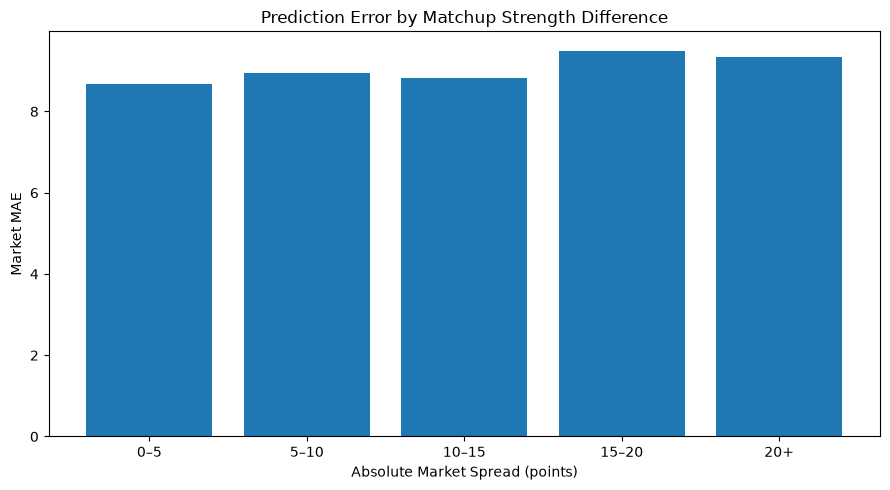

In [77]:
plt.figure(figsize=(9, 5))

plt.bar(
    spread_errors.index.astype(str),
    spread_errors["MAE"]
)

plt.xlabel("Absolute Market Spread (points)")
plt.ylabel("Market MAE")
plt.title("Prediction Error by Matchup Strength Difference")

plt.tight_layout()
plt.show()

In [78]:
rng = np.random.default_rng(42)

# Estimate noise from the training market residuals only.
noise_mean = market_train["market_residual"].mean()
noise_std = market_train["market_residual"].std()

# Use zero-mean noise to represent an unbiased market.
n_simulations = 2000

simulated_maes = []

for _ in range(n_simulations):

    random_errors = rng.normal(
        loc=0,
        scale=noise_std,
        size=len(market_val)
    )

    simulated_maes.append(
        np.mean(np.abs(random_errors))
    )

simulated_maes = np.array(simulated_maes)

print("Estimated noise SD:", round(noise_std, 3))
print("Simulated average MAE:", round(simulated_maes.mean(), 3))
print(
    "95% simulation range:",
    np.percentile(simulated_maes, [2.5, 97.5])
)

Estimated noise SD: 11.332
Simulated average MAE: 9.039
95% simulation range: [8.85336469 9.22239313]


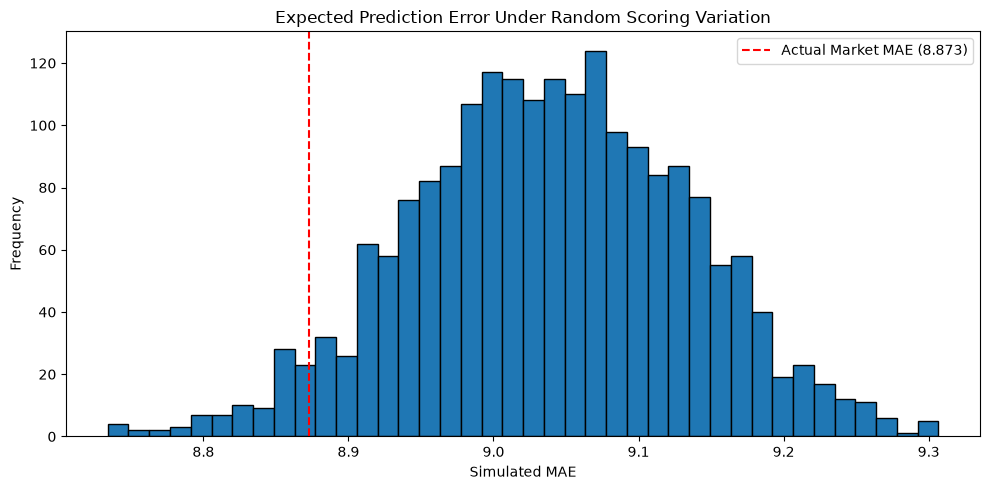

In [79]:
plt.figure(figsize=(10, 5))

plt.hist(
    simulated_maes,
    bins=40,
    edgecolor="black"
)

plt.axvline(
    market_mae,
    color="red",
    linestyle="--",
    label=f"Actual Market MAE ({market_mae:.3f})"
)

plt.xlabel("Simulated MAE")
plt.ylabel("Frequency")
plt.title("Expected Prediction Error Under Random Scoring Variation")

plt.legend()
plt.tight_layout()
plt.show()

In [80]:
def prepare_market_data(df):
    """
    Keep games with historical sportsbook lines and
    calculate the sportsbook's prediction error.
    """
    data = df.dropna(
        subset=["market_home_margin", target_col]
    ).copy()

    # Positive residual: home team outperformed the market.
    # Negative residual: home team underperformed.
    data["market_residual"] = (
        data[target_col] - data["market_home_margin"]
    )

    return data

In [81]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

def run_residual_fold(train_years, val_year):

    # Combine historical training seasons.
    train = pd.concat(
        [season_data[y] for y in train_years],
        ignore_index=True
    )

    val = season_data[val_year].copy()

    # Keep games with sportsbook lines.
    train = prepare_market_data(train)
    val = prepare_market_data(val)

    # Original basketball features.
    Xtr = train[feature_cols]
    Xva = val[feature_cols]

    # Our new prediction target.
    ytr = train["market_residual"]

    # Actual validation outcomes.
    actual = val[target_col].to_numpy()

    # Original sportsbook predictions.
    market = val["market_home_margin"].to_numpy()

    # Train a model to predict sportsbook errors.
    model = XGBRegressor(
        n_estimators=200,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=10,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(Xtr, ytr)

    # Predicted correction to the sportsbook margin.
    correction = model.predict(Xva)

    # Different amounts of correction.
    predictions = {
        "Market": market,
        "Full Correction": market + correction,
        "Half Correction": market + 0.5 * correction,
        "Quarter Correction": market + 0.25 * correction
    }

    results = []

    for name, pred in predictions.items():
        results.append({
            "Validation Season": val_year,
            "Model": name,
            "Games": len(val),
            "MAE": mean_absolute_error(actual, pred)
        })

    # Save predictions for further analysis.
    prediction_df = pd.DataFrame({
        "Validation Season": val_year,
        "Actual": actual,
        "Market": market,
        "Correction": correction,
        "Full Correction": predictions["Full Correction"],
        "Half Correction": predictions["Half Correction"],
        "Quarter Correction": predictions["Quarter Correction"]
    })

    return pd.DataFrame(results), prediction_df

In [82]:
residual_results = []
residual_predictions = []

for train_years, val_year in folds:

    results, predictions = run_residual_fold(
        train_years,
        val_year
    )

    residual_results.append(results)
    residual_predictions.append(predictions)

residual_results = pd.concat(
    residual_results,
    ignore_index=True
)

residual_predictions = pd.concat(
    residual_predictions,
    ignore_index=True
)

display(residual_results.round(4))

,Validation Season,Model,Games,MAE
0,2022,Market,5448,8.7896
1,2022,Full Correction,5448,8.7921
2,2022,Half Correction,5448,8.7880
3,2022,Quarter Correction,5448,8.7882
4,2023,Market,5690,8.8956
5,2023,Full Correction,5690,8.8962
6,2023,Half Correction,5690,8.8934
7,2023,Quarter Correction,5690,8.8942
8,2024,Market,5304,8.8729
9,2024,Full Correction,5304,8.8620


In [83]:
residual_summary = (
    residual_results
    .groupby("Model")
    .agg(
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Total_Games=("Games", "sum")
    )
    .sort_values("Mean_MAE")
)

display(residual_summary.round(4))

,Mean_MAE,Std_MAE,Total_Games
Model,,,
Half Correction,8.8487,0.0544,16442
Full Correction,8.8501,0.0531,16442
Quarter Correction,8.8502,0.0552,16442
Market,8.8527,0.0558,16442


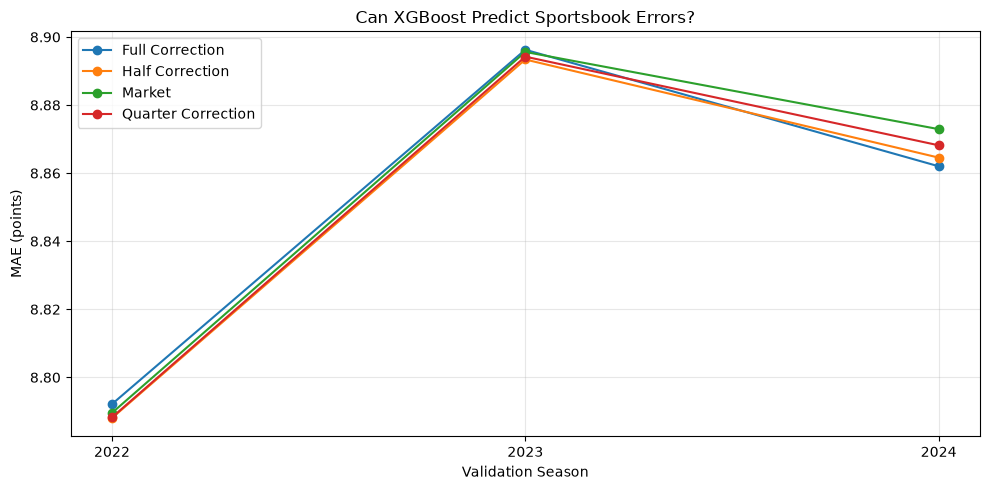

In [84]:
plt.figure(figsize=(10, 5))

for name, group in residual_results.groupby("Model"):

    group = group.sort_values("Validation Season")

    plt.plot(
        group["Validation Season"],
        group["MAE"],
        marker="o",
        label=name
    )

plt.xlabel("Validation Season")
plt.ylabel("MAE (points)")
plt.title("Can XGBoost Predict Sportsbook Errors?")

plt.xticks([2022, 2023, 2024])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Residual correlation: 0.0477


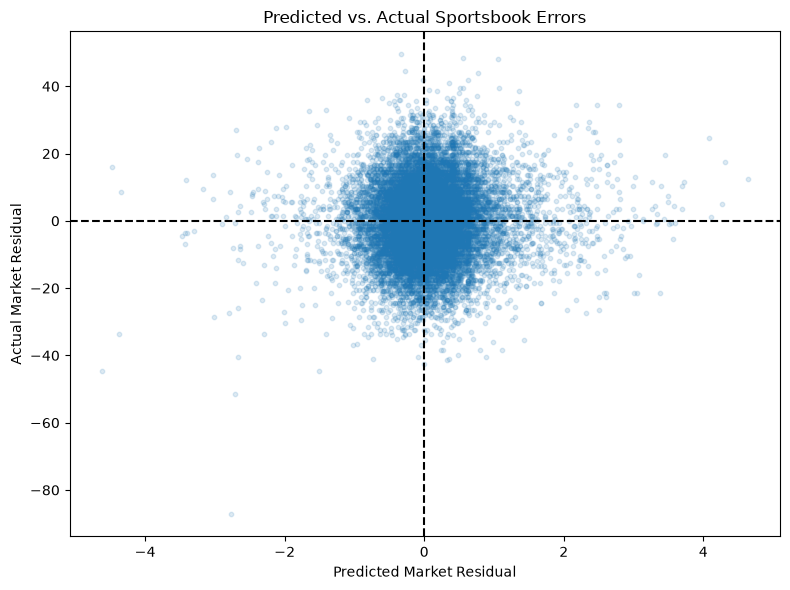

In [85]:
actual_residual = (
    residual_predictions["Actual"]
    - residual_predictions["Market"]
)

predicted_residual = residual_predictions["Correction"]

correlation = np.corrcoef(
    actual_residual,
    predicted_residual
)[0, 1]

print(f"Residual correlation: {correlation:.4f}")

plt.figure(figsize=(8, 6))

plt.scatter(
    predicted_residual,
    actual_residual,
    alpha=0.15,
    s=10
)

plt.axhline(0, color="black", linestyle="--")
plt.axvline(0, color="black", linestyle="--")

plt.xlabel("Predicted Market Residual")
plt.ylabel("Actual Market Residual")
plt.title("Predicted vs. Actual Sportsbook Errors")

plt.tight_layout()
plt.show()

In [86]:
bootstrap = paired_mae_bootstrap(
    residual_predictions["Actual"],
    residual_predictions["Market"],
    residual_predictions["Half Correction"]
)

print("MAE improvement:", round(bootstrap["Mean Improvement"], 4))
print(
    "95% interval:",
    round(bootstrap["CI Lower"], 4),
    "to",
    round(bootstrap["CI Upper"], 4)
)

MAE improvement: 0.004
95% interval: -0.0007 to 0.0087


# Prep For and Train Final Models

In [87]:
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge
from xgboost import XGBRegressor

# Directory for our final model artifacts
MODEL_DIR = Path("cbb_models")
MODEL_DIR.mkdir(exist_ok=True)

# Development seasons only: 2016-17 through 2023-24
development_df = pd.concat(
    [season_data[year] for year in range(2017, 2025)],
    ignore_index=True
)

X_dev = development_df[feature_cols].copy()
y_dev = development_df[target_col].copy()

print("Development games:", len(X_dev))
print("Original features:", X_dev.shape[1])

Development games: 42767
Original features: 267


In [88]:
final_lasso = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lasso", Lasso(
        alpha=0.31623,
        max_iter=20000,
        tol=1e-4
    ))
])

final_lasso.fit(X_dev, y_dev)

# Identify features with nonzero coefficients
coefficients = final_lasso.named_steps["lasso"].coef_

selected_mask = np.abs(coefficients) > 1e-6

linear_features = X_dev.columns[selected_mask].tolist()

print("Final linear feature count:", len(linear_features))
print(linear_features)

Final linear feature count: 25
['neutral_site', 'conference_game', 'home_avg_margin', 'diff_avg_margin', 'away_avg_possessions', 'diff_avg_pace', 'diff_avg_fg3_pct', 'home_avg_oreb_pct', 'diff_avg_oreb_pct', 'home_avg_assists', 'diff_avg_assists', 'diff_avg_blocks', 'diff_last5_blocks', 'home_avg_sos_margin', 'diff_avg_sos_margin', 'diff_avg_sor', 'diff_last5_sor', 'missing_away_avg_points_for', 'missing_diff_avg_points_for', 'missing_diff_last5_points_for', 'missing_diff_avg_points_against', 'missing_away_avg_pace', 'missing_diff_avg_pace', 'missing_diff_avg_off_eff', 'missing_home_rest_days']


In [89]:
final_ridge = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=100))
])

final_ridge.fit(
    X_dev[linear_features],
    y_dev
)

# Save the complete pipeline.
joblib.dump(
    final_ridge,
    MODEL_DIR / "ridge_model.joblib"
)

# Save feature names in their original order.
with open(MODEL_DIR / "linear_features.json", "w") as f:
    json.dump(linear_features, f, indent=4)

print("Ridge model and feature list saved.")

Ridge model and feature list saved.


In [90]:
xgb_params = dict(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    importance_type="gain"
)

ranking_model = XGBRegressor(**xgb_params)

ranking_model.fit(X_dev, y_dev)

# Rank features using gain importance.
importance = pd.Series(
    ranking_model.feature_importances_,
    index=X_dev.columns
).sort_values(ascending=False)

display(importance.head(30))

diff_avg_margin          0.152046
diff_avg_win             0.118013
diff_last5_margin        0.052631
diff_avg_sor             0.030014
diff_avg_off_eff         0.018299
diff_avg_sos_margin      0.014902
neutral_site             0.014389
diff_avg_sos_win         0.013863
home_avg_margin          0.013589
diff_last5_sos_margin    0.012628
diff_last5_sos_win       0.009735
away_all_games_played    0.009684
conference_game          0.009438
diff_avg_def_eff         0.009209
away_games_played        0.007428
away_avg_margin          0.007190
home_avg_sos_margin      0.006888
diff_avg_assists         0.006539
diff_avg_oreb_pct        0.006429
home_avg_off_eff         0.006205
home_games_played        0.006006
home_all_games_played    0.005996
home_avg_oreb_pct        0.005856
home_avg_sos_win         0.005619
diff_avg_fg3_pct         0.005455
away_avg_off_eff         0.005285
diff_avg_tov_pct         0.005202
home_avg_assists         0.005087
home_last5_off_eff       0.005075
home_avg_sor  

In [91]:
# Keep the 30 highest-ranked predictors.
xgb_features = importance.head(30).index.tolist()

print("Selected XGBoost features:")
for i, feature in enumerate(xgb_features, start=1):
    print(f"{i:2d}. {feature}")

# Save the list.
with open(MODEL_DIR / "xgboost_features.json", "w") as f:
    json.dump(xgb_features, f, indent=4)

Selected XGBoost features:
 1. diff_avg_margin
 2. diff_avg_win
 3. diff_last5_margin
 4. diff_avg_sor
 5. diff_avg_off_eff
 6. diff_avg_sos_margin
 7. neutral_site
 8. diff_avg_sos_win
 9. home_avg_margin
10. diff_last5_sos_margin
11. diff_last5_sos_win
12. away_all_games_played
13. conference_game
14. diff_avg_def_eff
15. away_games_played
16. away_avg_margin
17. home_avg_sos_margin
18. diff_avg_assists
19. diff_avg_oreb_pct
20. home_avg_off_eff
21. home_games_played
22. home_all_games_played
23. home_avg_oreb_pct
24. home_avg_sos_win
25. diff_avg_fg3_pct
26. away_avg_off_eff
27. diff_avg_tov_pct
28. home_avg_assists
29. home_last5_off_eff
30. home_avg_sor


In [92]:
final_xgb = XGBRegressor(**xgb_params)

final_xgb.fit(
    X_dev[xgb_features],
    y_dev
)

joblib.dump(
    final_xgb,
    MODEL_DIR / "xgboost_model.joblib"
)

print("XGBoost model saved.")

XGBoost model saved.


# Verify Saved Models

In [93]:
# Load the saved models and feature lists.
saved_ridge = joblib.load(
    MODEL_DIR / "ridge_model.joblib"
)

saved_xgb = joblib.load(
    MODEL_DIR / "xgboost_model.joblib"
)

with open(MODEL_DIR / "linear_features.json") as f:
    saved_linear_features = json.load(f)

with open(MODEL_DIR / "xgboost_features.json") as f:
    saved_xgb_features = json.load(f)

# Check using a few development examples only.
sample = X_dev.iloc[:10]

ridge_original = final_ridge.predict(
    sample[linear_features]
)

ridge_reloaded = saved_ridge.predict(
    sample[saved_linear_features]
)

xgb_original = final_xgb.predict(
    sample[xgb_features]
)

xgb_reloaded = saved_xgb.predict(
    sample[saved_xgb_features]
)

assert np.allclose(ridge_original, ridge_reloaded)
assert np.allclose(xgb_original, xgb_reloaded)

print("Both saved models verified successfully.")

Both saved models verified successfully.
